In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
import astropy.units as u


sns.set_context("talk")


In [2]:

# ============================================================
# USER INPUTS
# ============================================================

DATA_DIR = Path("fits_ready")

FILES = {
    "regular": {
        "filename": "FLAMES-30Dor-6563-reg.fits",
        "label": "Regular grid",
        "kind": "table",
    },
    "irregular": {
        "filename": "FLAMES-30Dor-6563-irr.fits",
        "label": "Irregular grid",
        "kind": "table",
    },
    "stellar": {
        "filename": "FLAMES-30Dor-6563-stellar.fits",
        "label": "Stellar grid",
        "kind": "table",
    },
    "complete": {
        "filename": "FLAMES-30Dor-6563-complete.fits",
        "label": "Complete sample",
        "kind": "table",
    },
    "all_in_regular_area": {
        "filename": "FLAMES-30Dor-6563-air.fits",
        "label": "All in regular area",
        "kind": "table",
    },
    "cube": {
        "filename": "FLAMES-30Dor-Ha-bin0.fits",
        "label": "Cube",
        "kind": "image",
    },
   "grid_0": {
         "filename": "FLAMES-30Dor-Ha-bin0-grid_0.fits",
          "label": "grid_0",
         "kind": "image",
    },
   "grid_1": {
         "filename": "FLAMES-30Dor-Ha-bin0-grid_1.fits",
          "label": "grid_1",
         "kind": "image",
    },
   "grid_2": {
         "filename": "FLAMES-30Dor-Ha-bin0-grid_2.fits",
          "label": "grid_2",
         "kind": "image",
    },
   "grid2matrix": {
         "filename": "FLAMES-30Dor-Ha-bin0-grid2matrix.fits",
          "label": "grid2matrix",
         "kind": "image",
    },
   "matrix2grid": {
         "filename": "FLAMES-30Dor-Ha-bin0-matrix2grid.fits",
          "label": "matrix2grid",
         "kind": "image",
    },
}

# Used later to select datasets for plots.
COMPARE = [
    "regular",
    "all_in_regular_area",
    "cube",
]

labels = {key: info["label"] for key, info in FILES.items()}

In [3]:
# ============================================================
# INSPECT FITS STRUCTURE
# ============================================================

HEADER_KEYS = [
    "OBJECT", "LINE", "BUNIT",
    "PIX", "PC", "BOX_SIZE",
    "SIG", "SIG2", "R0", "M", "S0", "NOISE",
]

inventory = []

for key, info in FILES.items():

    path = DATA_DIR / info["filename"]

    print(f"\n{'=' * 72}")
    print(f"{info['label']}: {path.name}")

    if not path.is_file():
        print(f"FILE NOT FOUND: {path}")
        continue

    with fits.open(path, memmap=False) as hdul:

        hdul.info()

        # Primary metadata, including comments that may explain units.
        print("\nSelected primary-header values:")

        for keyword in HEADER_KEYS:
            if keyword in hdul[0].header:
                value = hdul[0].header[keyword]
                comment = hdul[0].header.comments[keyword]
                print(f"  {keyword}: {value}  |  {comment}")

        for index, hdu in enumerate(hdul):

            shape = None if hdu.data is None else hdu.data.shape

            inventory.append({
                "Dataset": key,
                "HDU index": index,
                "HDU name": hdu.name,
                "Type": type(hdu).__name__,
                "Shape": shape,
                "BUNIT": hdu.header.get("BUNIT"),
            })

            if isinstance(hdu, (fits.BinTableHDU, fits.TableHDU)):
                print(f"\nTable HDU {index}: {hdu.name}")

                column_info = pd.DataFrame([
                    {
                        "Column": col.name,
                        "FITS format": col.format,
                        "Unit": col.unit,
                    }
                    for col in hdu.columns
                ])

                display(column_info)

                # Preview only three rows.
                display(Table(hdu.data[:3]))

            elif hdu.data is not None:
                print(
                    f"\nImage HDU {index}: {hdu.name}"
                    f" | shape={shape}"
                    f" | BUNIT={hdu.header.get('BUNIT', 'not specified')}"
                )

                # Show available coordinate-axis definitions.
                for keyword in (
                    "CTYPE1", "CTYPE2", "CUNIT1", "CUNIT2",
                    "CDELT1", "CDELT2",
                ):
                    if keyword in hdu.header:
                        print(f"  {keyword}: {hdu.header[keyword]}")

fits_inventory = pd.DataFrame(inventory)

display(fits_inventory)


Regular grid: FLAMES-30Dor-6563-reg.fits
Filename: fits_ready\FLAMES-30Dor-6563-reg.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      22   ()      
  1  FLAMES-30DOR-6563    1 BinTableHDU     19   269R x 5C   [D, D, D, D, D]   
  2  TABLE         1 BinTableHDU     23   27R x 7C   [D, D, D, D, D, D, D]   

Selected primary-header values:
  LINE: H$\alpha$  |  Emission line name
  PIX: 0  |  Instrument pixel scale
  PC: 0.24240684055476797  |  parsec conversion
  BOX_SIZE: 142.80212542988227  |  Observational box_size
  SIG: 13.848244238836372  |  Standard deviation vel map
  SIG2: 191.77386849846476  |  Vel variance map
  S0: 0.21816615649929116  |  Atmospheric seeing

Table HDU 1: FLAMES-30DOR-6563


,Column,FITS format,Unit
0,RAdeg,D,None
1,DEdeg,D,None
2,V_mean,D,None
3,log_F,D,None
4,sigma,D,None


RAdeg,DEdeg,V_mean,log_F,sigma
float64,float64,float64,float64,float64
84.9085833333319,-69.1221944444433,284.8002271176725,3.096595615046691,26.150175177656312
84.6905416666652,-69.1110833333322,301.48015187561043,4.150517262289552,15.903440886819016
84.9085833333319,-69.1110833333322,260.1260209893585,3.4856646881442934,21.96660444405096



Table HDU 2: TABLE


,Column,FITS format,Unit
0,log10 r,D,None
1,r,D,None
2,r_err,D,None
3,Unweighted B(r),D,None
4,Unweighted B(r)_err,D,None
5,Weighted B(r),D,None
6,Weighted B(r)_err,D,None


log10 r,r,r_err,Unweighted B(r),Unweighted B(r)_err,Weighted B(r),Weighted B(r)_err
float64,float64,float64,float64,float64,float64,float64
0.6838405007681142,4.8288142617024725,0.00769505869595632,24.41895191857478,6.292090831441218,23.915679821039603,6.317684437131124
0.6860487383870894,4.853429643724221,0.015106333608300403,342.7121386161764,155.96627333749407,304.8117256388658,148.7000298881679
0.9865978834778665,9.696117806617812,0.04095414802947411,279.41068364853163,26.878449489157813,281.3889841760936,27.20820442798536


... (48 outputs left out)


matrix2grid: FLAMES-30Dor-Ha-bin0-matrix2grid.fits
Filename: fits_ready\FLAMES-30Dor-Ha-bin0-matrix2grid.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      27   ()      
  1  MOM0          1 ImageHDU        32   (32, 30)   float64   
  2  MOM1          1 ImageHDU        32   (32, 30)   float64   
  3  MOM2          1 ImageHDU        32   (32, 30)   float64   
  4  MASK          1 ImageHDU        36   (32, 30)   uint8   
  5  TABLE         1 BinTableHDU     26   26R x 7C   [D, D, D, D, D, D, D]   

Selected primary-header values:
  LINE: H$\alpha$  |  Emission line name
  PIX: 20  |  Instrument pixel scale
  PC: 0.24240684055476797  |  parsec convertion
  BOX_SIZE: 150.46593192249028  |  Observational box_size
  S0: 0.09263955689991132  |  Atmospheric seeing

Image HDU 1: MOM0 | shape=(30, 32) | BUNIT=not specified
  CTYPE1: RA---TAN
  CTYPE2: DEC--TAN
  CUNIT1: deg
  CUNIT2: deg
  CDELT1: 1.0
  CDELT2: 1.0

Image HDU 2: MOM1 | shape

,Column,FITS format,Unit
0,log10 r,D,None
1,r,D,None
2,r_err,D,None
3,Unweighted B(r),D,None
4,Unweighted B(r)_err,D,None
5,Weighted B(r),D,None
6,Weighted B(r)_err,D,None


log10 r,r,r_err,Unweighted B(r),Unweighted B(r)_err,Weighted B(r),Weighted B(r)_err
float64,float64,float64,float64,float64,float64,float64
0.0016910826904525302,4.86705158766028,7.819532467146264e-06,123.92395497012015,36.20726270761243,80.49822598549524,85.87567697168612
0.3017574423198119,9.712528566166377,0.021591332443408787,183.0161634171442,18.153017973035162,222.86801061245433,89.26416442618454
0.34963459312846656,10.844498173692907,2.3547654114928407e-05,181.03463252169715,27.03390632923154,157.2701801831827,70.18635541719183


,Dataset,HDU index,HDU name,Type,Shape,BUNIT
0,regular,0,PRIMARY,PrimaryHDU,None,None
1,regular,1,FLAMES-30DOR-6563,BinTableHDU,"(269,)",None
2,regular,2,TABLE,BinTableHDU,"(27,)",None
3,irregular,0,PRIMARY,PrimaryHDU,None,None
4,irregular,1,FLAMES-30DOR-6563,BinTableHDU,"(112,)",None
5,irregular,2,TABLE,BinTableHDU,"(40,)",None
6,stellar,0,PRIMARY,PrimaryHDU,None,None
7,stellar,1,FLAMES-30DOR-6563,BinTableHDU,"(988,)",None
8,stellar,2,TABLE,BinTableHDU,"(42,)",None
9,complete,0,PRIMARY,PrimaryHDU,None,None


In [4]:
# ============================================================
# LOAD ALL FITS DATASETS
# ============================================================

def load_flames_dataset(path, info):
    """Load stored values without filtering or unit conversion."""

    result = {
        "path": path,
        "label": info["label"],
        "kind": info["kind"],
    }

    with fits.open(path, memmap=False) as hdul:

        result["header"] = hdul[0].header.copy()

        # Keep every extension header for later metadata/WCS checks.
        result["extension_headers"] = {
            hdu.name: hdu.header.copy()
            for hdu in hdul[1:]
        }

        # Structure function: same extension name for all datasets.
        result["sf"] = Table.read(hdul["TABLE"]).to_pandas()

        if info["kind"] == "table":

            if not isinstance(hdul[1], fits.BinTableHDU):
                raise TypeError(f"{path.name}: HDU 1 is not a binary table.")

            observations = Table.read(hdul[1]).to_pandas()

            required = ["RAdeg", "DEdeg", "V_mean", "log_F", "sigma"]
            missing = [
                column for column in required
                if column not in observations.columns
            ]

            if missing:
                raise ValueError(
                    f"{path.name}: missing observation columns {missing}"
                )

            result["observations"] = observations

        elif info["kind"] == "image":

            result["maps"] = {
                name: np.array(hdul[name].data, dtype=float, copy=True)
                for name in ["MOM0", "MOM1", "MOM2"]
            }

            shapes = {array.shape for array in result["maps"].values()}

            if len(shapes) != 1:
                raise ValueError(f"{path.name}: moment-map shapes differ.")

            # Preserve the original mask values; do not apply it yet.
            result["mask"] = (
                np.array(hdul["MASK"].data, copy=True)
                if "MASK" in hdul
                else None
            )

            if result["mask"] is not None:
                if result["mask"].shape != result["maps"]["MOM1"].shape:
                    raise ValueError(f"{path.name}: mask shape differs.")

        else:
            raise ValueError(f"Unknown dataset kind: {info['kind']}")

    return result


data = {
    key: load_flames_dataset(DATA_DIR / info["filename"], info)
    for key, info in FILES.items()
}

print("Loaded:", ", ".join(data))

Loaded: regular, irregular, stellar, complete, all_in_regular_area, cube, grid_0, grid_1, grid_2, grid2matrix, matrix2grid


In [5]:
# ============================================================
# SUMMARY OF LOADED DATA
# ============================================================

summary_rows = []

for key, dataset in data.items():

    if dataset["kind"] == "table":
        obs = dataset["observations"]

        velocity = obs["V_mean"].to_numpy(dtype=float)
        sigma = obs["sigma"].to_numpy(dtype=float)
        shape = f"{len(obs)} spectra"

    else:
        velocity = dataset["maps"]["MOM1"]
        sigma = dataset["maps"]["MOM2"]
        shape = str(velocity.shape)

    sf = dataset["sf"]
    header = dataset["header"]

    summary_rows.append({
        "Dataset": dataset["label"],
        "Shape / size": shape,
        "Finite velocities": int(np.isfinite(velocity).sum()),
        "Finite sigma": int(np.isfinite(sigma).sum()),
        "SF bins stored": len(sf),
        "Finite B(r)": int(
            np.isfinite(sf["Unweighted B(r)"].to_numpy(dtype=float)).sum()
        ),
        "Header SIG": header.get("SIG", np.nan),
        "Header SIG2": header.get("SIG2", np.nan),
        "PIX": header.get("PIX", np.nan),
        "PC": header.get("PC", np.nan),
    })

display(pd.DataFrame(summary_rows).set_index("Dataset"))

# Inspect the cube mask without assuming its meaning.
mask = data["cube"]["mask"]

if mask is not None:
    values, counts = np.unique(mask, return_counts=True)

    display(pd.DataFrame({
        "Mask value": values,
        "Number of pixels": counts,
    }))

,Shape / size,Finite velocities,Finite sigma,SF bins stored,Finite B(r),Header SIG,Header SIG2,PIX,PC
Dataset,,,,,,,,,
Regular grid,269 spectra,269,269,27,27,13.848244,191.773868,0,0.242407
Irregular grid,112 spectra,112,112,40,40,15.036899,226.108318,0,0.242407
Stellar grid,988 spectra,988,986,42,42,13.504407,182.369011,0,0.242407
Complete sample,1369 spectra,1369,1367,42,42,13.813512,190.813115,0,0.242407
All in regular area,934 spectra,934,933,39,39,16.080750,258.590536,0,0.242407
Cube,"(30, 32)",960,960,32,26,11.604178,134.656949,20,0.242407
grid_0,"(30, 32)",960,960,32,21,11.604178,134.656949,20,0.242407
grid_1,"(30, 32)",960,960,32,21,11.604178,134.656949,20,0.242407
grid_2,"(30, 32)",269,269,32,24,NaN,NaN,20,0.242407


,Mask value,Number of pixels
0,0,1
1,1,959


In [6]:
# Grid observations
df_regular = data["regular"]["observations"]
df_complete = data["complete"]["observations"]

# Cube maps: MOM2 is already corrected sigma_LOS
sb = data["cube"]["maps"]["MOM0"]
vv = data["cube"]["maps"]["MOM1"]
ss = data["cube"]["maps"]["MOM2"]

# Structure-function tables
sf_regular = data["regular"]["sf"]
sf_cube = data["cube"]["sf"]

display(df_regular.head())
display(sf_regular.head())
display(sf_cube.head())

,RAdeg,DEdeg,V_mean,log_F,sigma
0,84.908583,-69.122194,284.800227,3.096596,26.150175
1,84.690542,-69.111083,301.480152,4.150517,15.903441
2,84.908583,-69.111083,260.126021,3.485665,21.966604
3,84.597125,-69.099972,265.728417,3.638061,38.107156
4,84.908583,-69.099972,266.876657,3.627476,12.747237


,log10 r,r,r_err,Unweighted B(r),Unweighted B(r)_err,Weighted B(r),Weighted B(r)_err
0,0.683841,4.828814,0.007695,24.418952,6.292091,23.915680,6.317684
1,0.686049,4.853430,0.015106,342.712139,155.966273,304.811726,148.700030
2,0.986598,9.696118,0.040954,279.410684,26.878449,281.388984,27.208204
3,1.035001,10.839302,0.010047,296.354439,43.504964,295.931018,42.997571
4,1.150417,14.138945,0.453645,317.312719,31.179550,315.107137,31.075080


,log10 r,Sum dv^2,Sum weights,Sum w * dv^2,N pairs,Unweighted B(r),Weighted B(r)
0,0.00,104824.390203,7.824127e+09,7.783362e+11,928,112.957317,99.478994
1,0.05,0.000000,0.000000e+00,0.000000e+00,0,NaN,NaN
2,0.10,0.000000,0.000000e+00,0.000000e+00,0,NaN,NaN
3,0.15,241540.653197,1.475118e+10,2.755112e+12,1794,134.638045,186.772281
4,0.20,0.000000,0.000000e+00,0.000000e+00,0,NaN,NaN


In [7]:
# ============================================================
# APPLY CUBE MASK: 0 = EXCLUDED, 1 = VALID
# ============================================================

cube = data["cube"]

if cube["mask"] is None:
    raise ValueError("The cube has no MASK extension.")

excluded = cube["mask"] == 0

# Rebuild from the original, unmasked maps.
cube["maps_masked"] = {
    name: np.where(excluded, np.nan, image)
    for name, image in cube["maps"].items()
}

sb = cube["maps_masked"]["MOM0"]
vv = cube["maps_masked"]["MOM1"]
ss = cube["maps_masked"]["MOM2"]

print(f"Total pixels:    {excluded.size}")
print(f"Excluded pixels: {excluded.sum()}")
print(f"Unmasked pixels: {(~excluded).sum()}")

Total pixels:    960
Excluded pixels: 1
Unmasked pixels: 959


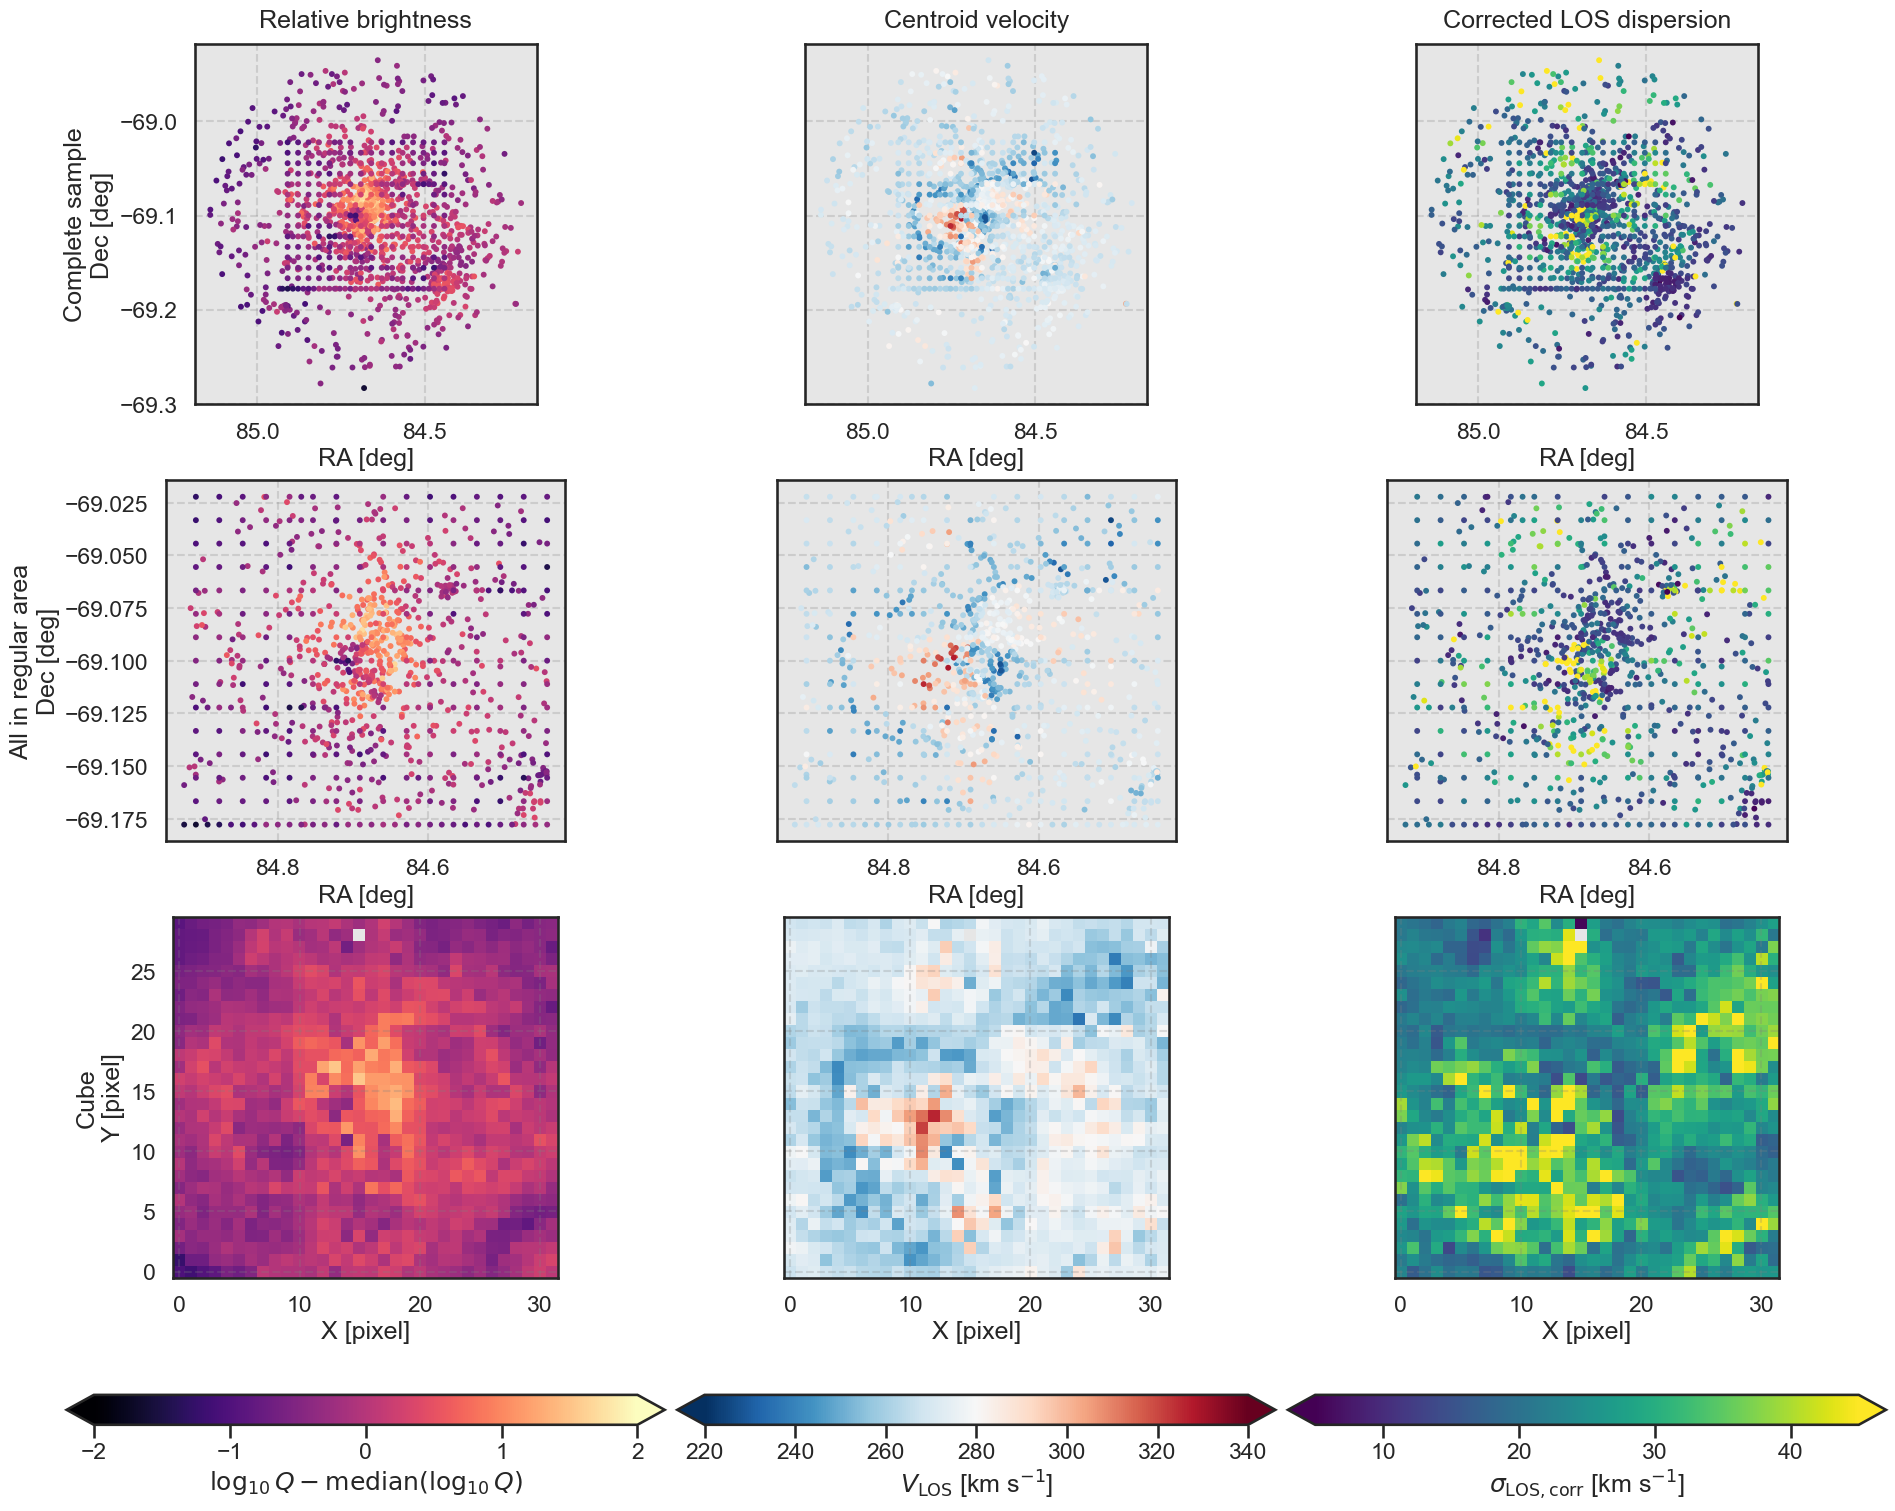

In [8]:


from matplotlib.colors import Normalize

sns.set_context("talk")

# ============================================================
# 1. USER INPUTS
# ============================================================

COMPARE = ["complete", "all_in_regular_area", "cube"]

FIGSIZE = (19, 15)
MARKER_SIZE = 18

BRIGHTNESS_LIMITS = (-2, 2)
VELOCITY_LIMITS = (220, 340)      # km/s
SIGMA_LIMITS = (5, 45)           # km/s

CMAPS = ["magma", "RdBu_r", "viridis"]

# ============================================================
# 2. PREPARE MAPS
# ============================================================

def center_log_brightness(log_values):
    """Subtract the median of finite logarithmic brightness values."""
    values = np.asarray(log_values, dtype=float).copy()
    finite = np.isfinite(values)

    values[~finite] = np.nan

    if finite.any():
        values[finite] -= np.median(values[finite])

    return values


prepared = {}

for key in COMPARE:
    dataset = data[key]

    if dataset["kind"] == "table":
        obs = dataset["observations"]

        prepared[key] = {
            "x": obs["RAdeg"].to_numpy(dtype=float),
            "y": obs["DEdeg"].to_numpy(dtype=float),
            "values": [
                center_log_brightness(obs["log_F"]),
                obs["V_mean"].to_numpy(dtype=float),
                obs["sigma"].to_numpy(dtype=float),
            ],
        }

    else:
        # These maps already exclude MASK == 1 pixels.
        maps = dataset["maps_masked"]

        intensity = maps["MOM0"]
        log_intensity = np.full(intensity.shape, np.nan)

        positive = np.isfinite(intensity) & (intensity > 0)
        log_intensity[positive] = np.log10(intensity[positive])

        prepared[key] = {
            "values": [
                center_log_brightness(log_intensity),
                maps["MOM1"],
                maps["MOM2"],    # Already corrected sigma_LOS
            ],
        }

# ============================================================
# 3. COMMON COLOR SCALES
# ============================================================

norms = [
    Normalize(*BRIGHTNESS_LIMITS),
    Normalize(*VELOCITY_LIMITS),
    Normalize(*SIGMA_LIMITS),
]

column_titles = [
    "Relative brightness",
    "Centroid velocity",
    "Corrected LOS dispersion",
]

colorbar_labels = [
    r"$\log_{10} Q - \mathrm{median}(\log_{10} Q)$",
    r"$V_{\mathrm{LOS}}$ [km s$^{-1}$]",
    r"$\sigma_{\mathrm{LOS,corr}}$ [km s$^{-1}$]",
]

# ============================================================
# 4. PLOT 3 × 3 GRID
# ============================================================

with sns.axes_style("white"):
    fig, axes = plt.subplots(
        3, 3,
        figsize=FIGSIZE,
        constrained_layout=True,
        sharex="row",
        sharey="row",
    )

    for row, key in enumerate(COMPARE):
        dataset = data[key]
        plot = prepared[key]

        for col, values in enumerate(plot["values"]):
            ax = axes[row, col]

            if dataset["kind"] == "table":
                ra = plot["x"]
                dec = plot["y"]

                valid = (
                    np.isfinite(ra)
                    & np.isfinite(dec)
                    & np.isfinite(values)
                )

                ax.scatter(
                    ra[valid],
                    dec[valid],
                    c=values[valid],
                    s=MARKER_SIZE,
                    cmap=CMAPS[col],
                    norm=norms[col],
                    edgecolors="none",
                )

                # Correct the visual aspect for RA convergence.
                finite_pos = np.isfinite(ra) & np.isfinite(dec)
                dec_ref = np.median(dec[finite_pos])
                ax.set_aspect(
                    1 / np.cos(np.deg2rad(dec_ref)),
                    adjustable="box",
                )

                ax.set_xlabel("RA [deg]")
                ax.ticklabel_format(
                    axis="both",
                    style="plain",
                    useOffset=False,
                )

            else:
                ax.imshow(
                    np.ma.masked_invalid(values),
                    origin="lower",
                    interpolation="nearest",
                    cmap=CMAPS[col],
                    norm=norms[col],
                    aspect="equal",
                )

                ax.set_xlabel("X [pixel]")

            ax.set_facecolor("0.90")
            ax.grid(color="0.5", alpha=0.25, linestyle="--")

            if row == 0:
                ax.set_title(column_titles[col], pad=12)

            if col == 0:
                coordinate_label = (
                    "Dec [deg]"
                    if dataset["kind"] == "table"
                    else "Y [pixel]"
                )
                ax.set_ylabel(
                    f"{dataset['label']}\n{coordinate_label}"
                )

        # Invert shared RA axis once per table row.
        if dataset["kind"] == "table":
            axes[row, 0].invert_xaxis()

    # One shared colorbar per quantity.
    for col in range(3):
        mappable = plt.cm.ScalarMappable(
            norm=norms[col],
            cmap=CMAPS[col],
        )

        cbar = fig.colorbar(
            mappable,
            ax=axes[:, col].tolist(),
            orientation="horizontal",
            fraction=0.035,
            pad=0.04,
            extend="both",
        )

        cbar.set_label(colorbar_labels[col])

    plt.show()

In [9]:
for name in ["MOM0", "MOM1", "MOM2"]:
    raw = data["cube"]["maps"][name]
    masked = data["cube"]["maps_masked"][name]

    print(
        f"{name}: shape={raw.shape}, "
        f"finite before mask={np.isfinite(raw).sum()}, "
        f"finite after mask={np.isfinite(masked).sum()}"
    )

MOM0: shape=(30, 32), finite before mask=960, finite after mask=959
MOM1: shape=(30, 32), finite before mask=960, finite after mask=959
MOM2: shape=(30, 32), finite before mask=960, finite after mask=959


In [10]:
data = {
    key: load_flames_dataset(DATA_DIR / info["filename"], info)
    for key, info in FILES.items()
}

cube_wcs = WCS(
    data["cube"]["extension_headers"]["MOM0"]
).celestial

print("Cube has celestial WCS:", cube_wcs.has_celestial)

Cube has celestial WCS: True


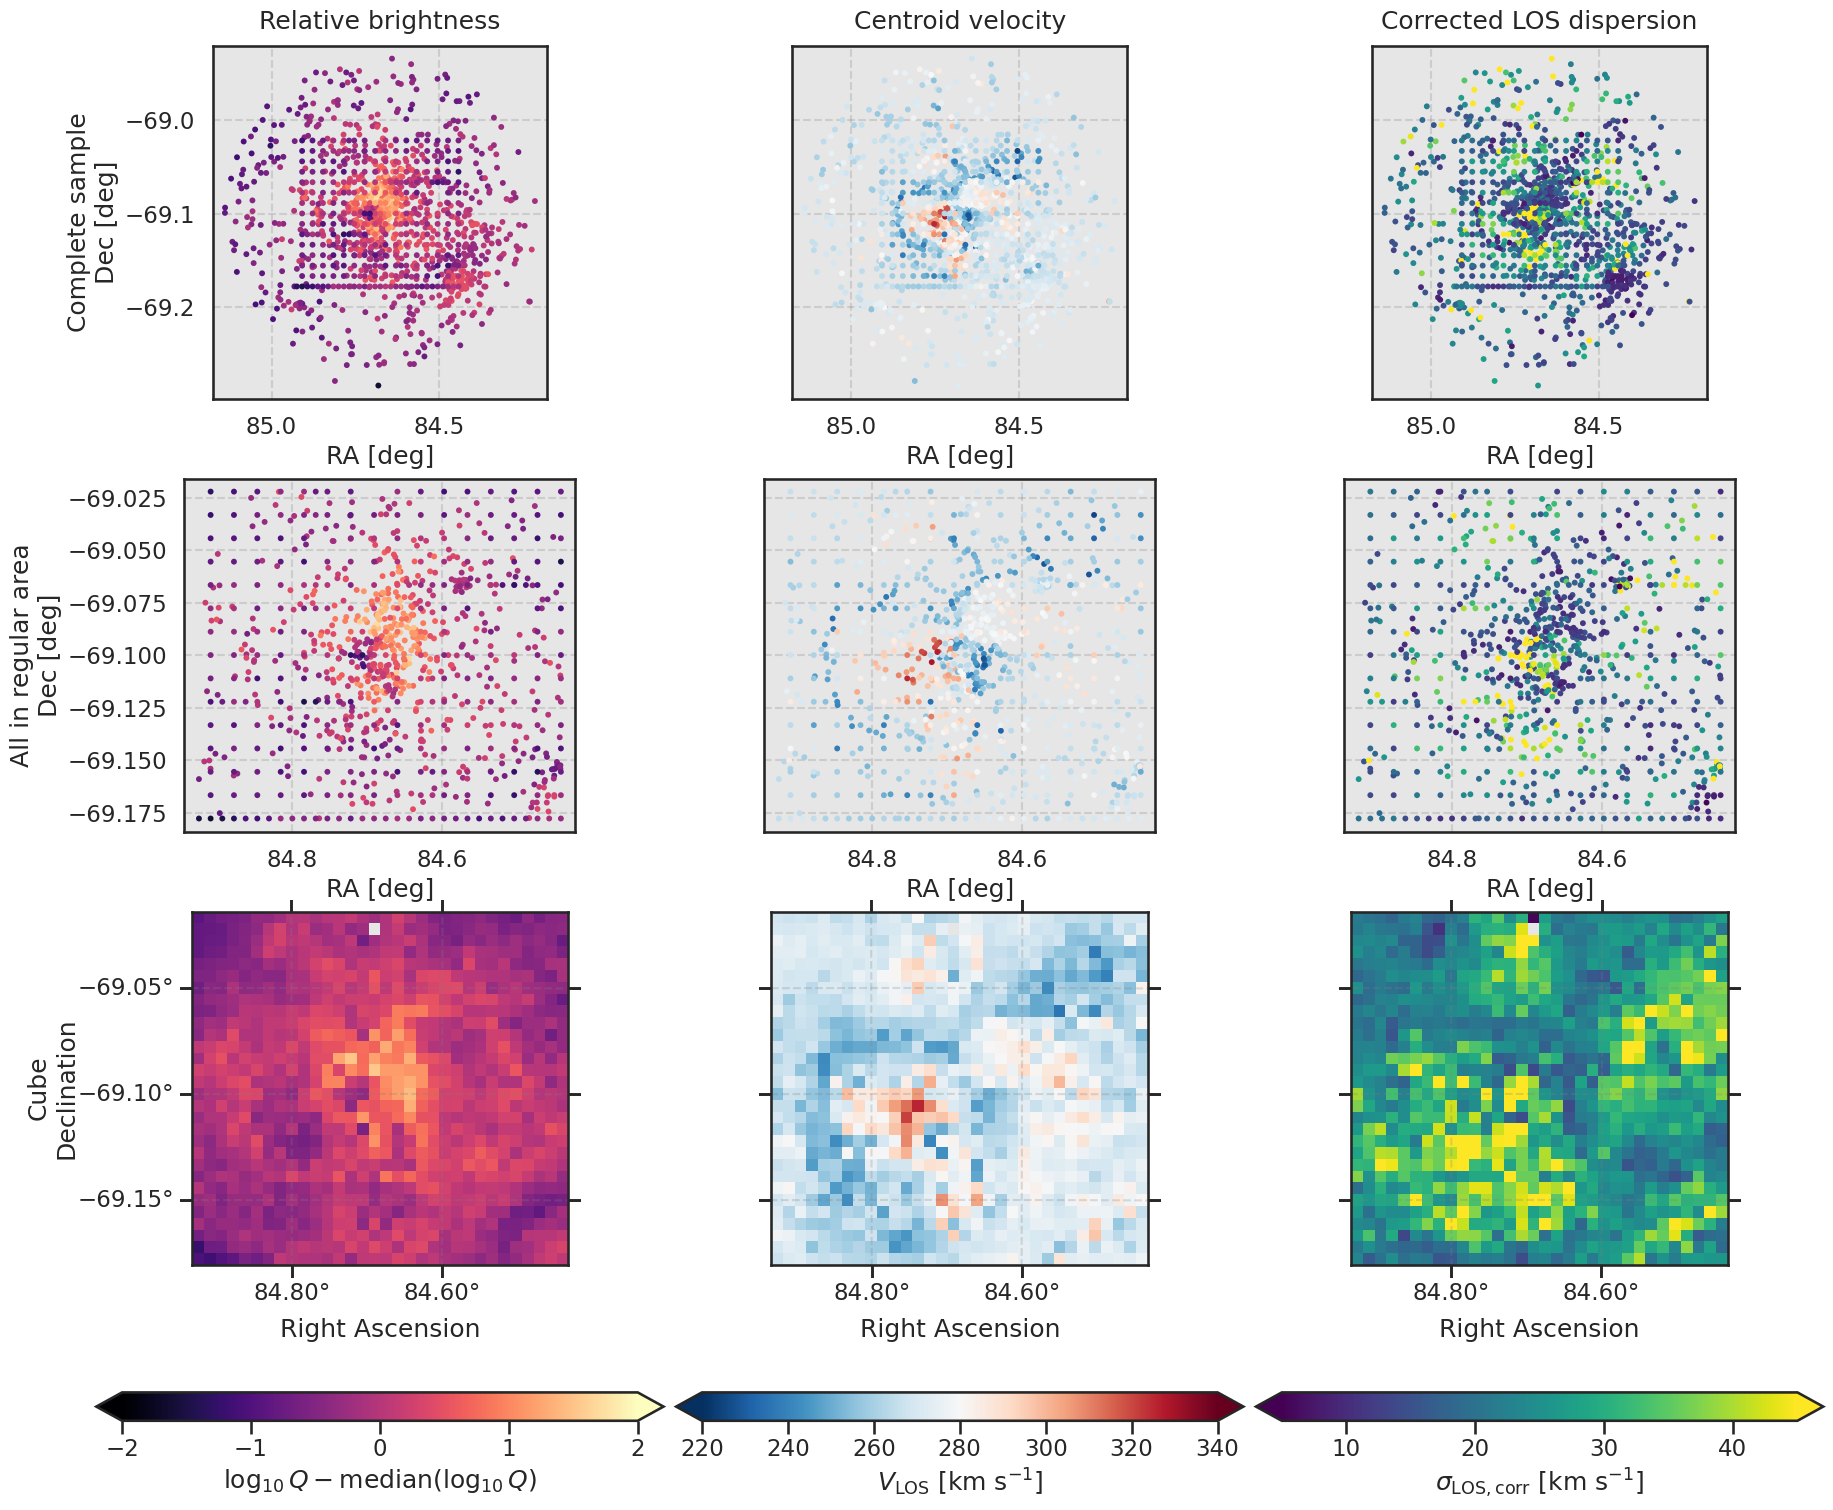

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from astropy.wcs import WCS
from matplotlib.colors import Normalize

sns.set_context("talk")

# ============================================================
# 1. USER INPUTS
# ============================================================

COMPARE = ["complete", "all_in_regular_area", "cube"]

FIGSIZE = (19, 15)
MARKER_SIZE = 18

BRIGHTNESS_LIMITS = (-2, 2)
VELOCITY_LIMITS = (220, 340)      # km/s
SIGMA_LIMITS = (5, 45)           # km/s

CMAPS = ["magma", "RdBu_r", "viridis"]

column_titles = [
    "Relative brightness",
    "Centroid velocity",
    "Corrected LOS dispersion",
]

colorbar_labels = [
    r"$\log_{10} Q - \mathrm{median}(\log_{10} Q)$",
    r"$V_{\mathrm{LOS}}$ [km s$^{-1}$]",
    r"$\sigma_{\mathrm{LOS,corr}}$ [km s$^{-1}$]",
]

norms = [
    Normalize(*BRIGHTNESS_LIMITS),
    Normalize(*VELOCITY_LIMITS),
    Normalize(*SIGMA_LIMITS),
]

# ============================================================
# 2. PREPARE OBSERVATIONS AND CUBE MAPS
# ============================================================

def center_log_brightness(log_values):
    values = np.asarray(log_values, dtype=float).copy()
    finite = np.isfinite(values)
    values[~finite] = np.nan

    if finite.any():
        values[finite] -= np.median(values[finite])

    return values


prepared = {}

for key in COMPARE:
    dataset = data[key]

    if dataset["kind"] == "table":
        obs = dataset["observations"]

        ra = obs["RAdeg"].to_numpy(dtype=float)
        dec = obs["DEdeg"].to_numpy(dtype=float)

        finite_pos = np.isfinite(ra) & np.isfinite(dec)

        if not finite_pos.any():
            raise ValueError(f"{key}: no finite coordinates.")

        ra_min, ra_max = ra[finite_pos].min(), ra[finite_pos].max()
        dec_min, dec_max = dec[finite_pos].min(), dec[finite_pos].max()

        pad_ra = max(0.04 * (ra_max - ra_min), 1e-6)
        pad_dec = max(0.04 * (dec_max - dec_min), 1e-6)

        prepared[key] = {
            "ra": ra,
            "dec": dec,
            "finite_pos": finite_pos,
            "dec_ref": np.median(dec[finite_pos]),
            "xlim": (ra_max + pad_ra, ra_min - pad_ra),
            "ylim": (dec_min - pad_dec, dec_max + pad_dec),
            "values": [
                center_log_brightness(obs["log_F"]),
                obs["V_mean"].to_numpy(dtype=float),
                obs["sigma"].to_numpy(dtype=float),
            ],
        }

    elif dataset["kind"] == "image":
        mask = dataset["mask"]

        if mask is None:
            raise ValueError(f"{key}: MASK extension is missing.")

        excluded = mask == 0

        maps = {
            name: np.where(excluded, np.nan, image)
            for name, image in dataset["maps"].items()
        }

        intensity = maps["MOM0"]
        log_intensity = np.full(intensity.shape, np.nan)

        positive = np.isfinite(intensity) & (intensity > 0)
        log_intensity[positive] = np.log10(intensity[positive])

        # Use each image extension's celestial WCS.
        map_wcs = [
            WCS(dataset["extension_headers"][name]).celestial
            for name in ["MOM0", "MOM1", "MOM2"]
        ]

        if not all(w.has_celestial for w in map_wcs):
            raise ValueError(
                f"{key}: a moment extension lacks celestial WCS. "
                "Check the exported headers and reload data."
            )

        prepared[key] = {
            "wcs": map_wcs,
            "values": [
                center_log_brightness(log_intensity),
                maps["MOM1"],
                maps["MOM2"],  # Already corrected sigma_LOS
            ],
        }

    else:
        raise ValueError(f"Unknown dataset kind: {dataset['kind']}")

# ============================================================
# 3. CREATE AXES
# ============================================================

with sns.axes_style("white"):

    fig = plt.figure(
        figsize=FIGSIZE,
        constrained_layout=True,
    )

    gs = fig.add_gridspec(len(COMPARE), 3)
    axes = np.empty((len(COMPARE), 3), dtype=object)

    for row, key in enumerate(COMPARE):
        for col in range(3):
            if data[key]["kind"] == "image":
                axes[row, col] = fig.add_subplot(
                    gs[row, col],
                    projection=prepared[key]["wcs"][col],
                )
            else:
                axes[row, col] = fig.add_subplot(gs[row, col])

    # ========================================================
    # 4. DRAW MAPS
    # ========================================================

    for row, key in enumerate(COMPARE):
        dataset = data[key]
        plot = prepared[key]

        for col, values in enumerate(plot["values"]):
            ax = axes[row, col]
            values = np.asarray(values, dtype=float)

            if dataset["kind"] == "table":
                valid = plot["finite_pos"] & np.isfinite(values)

                ax.scatter(
                    plot["ra"][valid],
                    plot["dec"][valid],
                    c=values[valid],
                    s=MARKER_SIZE,
                    cmap=CMAPS[col],
                    norm=norms[col],
                    edgecolors="none",
                )

                # Common spatial extent within each table row.
                # Reversed limits put increasing RA to the left.
                ax.set_xlim(*plot["xlim"])
                ax.set_ylim(*plot["ylim"])

                ax.set_aspect(
                    1 / np.cos(np.deg2rad(plot["dec_ref"])),
                    adjustable="box",
                )

                ax.set_xlabel("RA [deg]")
                ax.ticklabel_format(
                    axis="both",
                    style="plain",
                    useOffset=False,
                )

                if col == 0:
                    ax.set_ylabel(
                        f"{dataset['label']}\nDec [deg]"
                    )
                else:
                    ax.tick_params(axis="y", labelleft=False)

                ax.grid(
                    color="0.5",
                    alpha=0.25,
                    linestyle="--",
                )

            else:
                if values.ndim != 2:
                    raise ValueError(
                        f"{key}: expected a 2D map, got {values.shape}."
                    )

                ny, nx = values.shape

                ax.imshow(
                    np.ma.masked_invalid(values),
                    origin="lower",
                    interpolation="nearest",
                    cmap=CMAPS[col],
                    norm=norms[col],
                    aspect="equal",
                )

                ax.set_xlim(-0.5, nx - 0.5)
                ax.set_ylim(-0.5, ny - 0.5)

                #ax.coords[0].set_major_formatter("hh:mm:ss")
                #ax.coords[1].set_major_formatter("dd:mm:ss")

                ax.coords[0].set_format_unit(u.deg)
                ax.coords[1].set_format_unit(u.deg)
                
                ax.coords[0].set_major_formatter("d.dd")
                ax.coords[1].set_major_formatter("d.dd")
                
                ax.coords[0].set_axislabel("RA [deg]")
                ax.coords[1].set_axislabel(
                    f"{dataset['label']}\nDec [deg]" if col == 0 else ""
                )
                
                ax.coords[0].set_axislabel("Right Ascension")
                ax.coords[0].set_ticks(number=4)
                ax.coords[1].set_ticks(number=4)

                ax.coords[0].set_ticklabel(exclude_overlapping=True)
                ax.coords[1].set_ticklabel(exclude_overlapping=True)

                if col == 0:
                    ax.coords[1].set_axislabel(
                        f"{dataset['label']}\nDeclination"
                    )
                else:
                    ax.coords[1].set_axislabel("")
                    ax.coords[1].set_ticklabel_visible(False)

                ax.coords.grid(
                    color="0.5",
                    alpha=0.25,
                    linestyle="--",
                )

                # Do not invert the cube RA axis:
                # its orientation is already encoded in the WCS.

            ax.set_facecolor("0.90")

            if row == 0:
                ax.set_title(column_titles[col], pad=12)

    # ========================================================
    # 5. SHARED COLORBARS
    # ========================================================

    for col in range(3):
        mappable = plt.cm.ScalarMappable(
            norm=norms[col],
            cmap=CMAPS[col],
        )

        cbar = fig.colorbar(
            mappable,
            ax=axes[:, col].tolist(),
            orientation="horizontal",
            fraction=0.035,
            pad=0.04,
            extend="both",
        )

        cbar.set_label(colorbar_labels[col])


output_dir = Path("Imgs")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "FLAMES_maps_comparison.pdf",
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    output_dir / "FLAMES_maps_comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

,,N,Median,Std
Quantity,Dataset,,,
brightness,Complete sample,1369,0.000,0.619
velocity,Complete sample,1369,268.565,13.808
sigma,Complete sample,1285,17.466,8.164
brightness,All in regular area,934,0.000,0.646
velocity,All in regular area,934,266.793,16.072
sigma,All in regular area,872,17.630,8.551
brightness,Cube,959,0.000,0.397
velocity,Cube,959,268.901,11.473
sigma,Cube,918,26.275,6.716


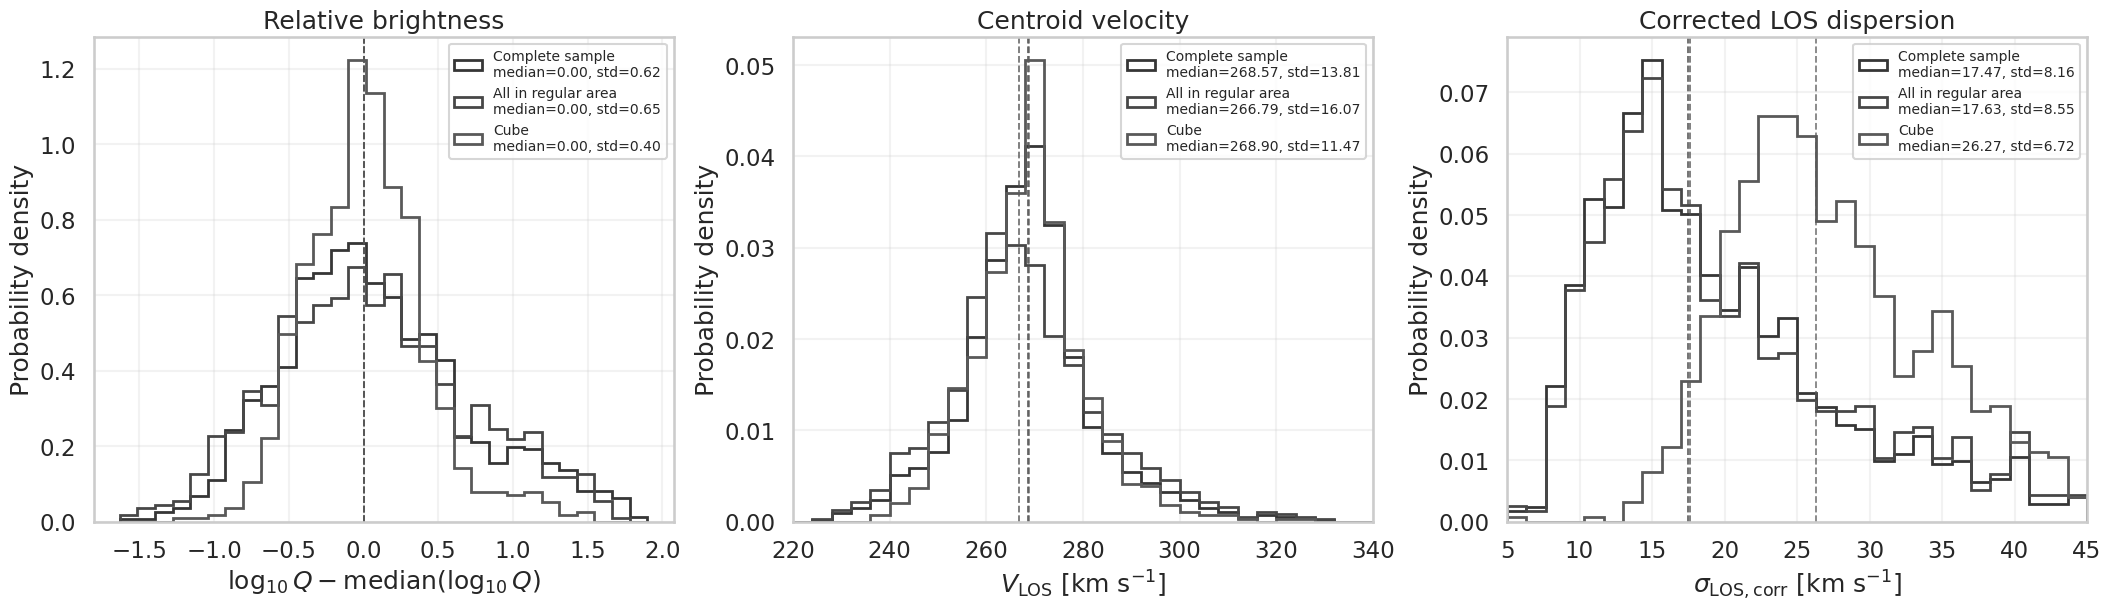

In [12]:

# ============================================================
# 1. USER INPUTS
# ============================================================

COMPARE = [
 #   "regular",
 #   "irregular",
 #   "stellar",
    "complete",
    "all_in_regular_area",
    "cube",
]

FIGSIZE = (21, 6)
N_BINS = 30

# Inclusive selection limits.
# Histograms and statistics use the same selected values.
LIMITS = {
    "brightness": None,         # Example: (-2, 2)
    "velocity": (220, 340),
    "sigma": (5, 45),
}

# Population standard deviation of the selected values.
DDOF = 0

# ============================================================
# 2. PREPARE DISTRIBUTIONS FROM LOADED FITS DATA
# ============================================================

def center_log_brightness(values):
    values = np.asarray(values, dtype=float).copy()
    finite = np.isfinite(values)
    values[~finite] = np.nan

    if finite.any():
        values[finite] -= np.median(values[finite])

    return values


hist_data = {}

for key in COMPARE:
    dataset = data[key]

    if dataset["kind"] == "table":
        obs = dataset["observations"]

        hist_data[key] = {
            "brightness": center_log_brightness(
                obs["log_F"].to_numpy(dtype=float)
            ),
            "velocity": obs["V_mean"].to_numpy(dtype=float),
            "sigma": obs["sigma"].to_numpy(dtype=float),
        }

    else:
        # Mask convention: 0 = excluded, 1 = valid.
        if dataset["mask"] is None:
            raise ValueError(f"{key}: missing MASK extension.")

        excluded = dataset["mask"] == 0

        maps = {
            name: np.where(excluded, np.nan, image)
            for name, image in dataset["maps"].items()
        }

        intensity = maps["MOM0"].ravel()
        log_intensity = np.full(intensity.shape, np.nan)

        positive = np.isfinite(intensity) & (intensity > 0)
        log_intensity[positive] = np.log10(intensity[positive])

        hist_data[key] = {
            "brightness": center_log_brightness(log_intensity),
            "velocity": maps["MOM1"].ravel(),
            "sigma": maps["MOM2"].ravel(),  # Already corrected sigma
        }

# ============================================================
# 3. SELECT VALUES AND COMPUTE STATISTICS
# ============================================================

variables = ["brightness", "velocity", "sigma"]

selected = {}
statistics = []

for key in COMPARE:
    selected[key] = {}

    for variable in variables:
        values = np.asarray(hist_data[key][variable], dtype=float)

        valid = np.isfinite(values)

        if variable == "sigma":
            valid &= values >= 0

        limits = LIMITS[variable]

        if limits is not None:
            low, high = limits
            if low >= high:
                raise ValueError(f"Invalid limits for {variable}.")
            valid &= (values >= low) & (values <= high)

        x = values[valid]
        selected[key][variable] = x

        statistics.append({
            "Key": key,
            "Dataset": data[key]["label"],
            "Quantity": variable,
            "N": len(x),
            "Median": np.median(x) if len(x) else np.nan,
            "Std": np.std(x, ddof=DDOF) if len(x) > DDOF else np.nan,
        })

stats = pd.DataFrame(statistics)

# Stable colors even when COMPARE changes.
all_keys = list(data)
#palette = dict(zip(
#    all_keys,
#    sns.color_palette("colorblind", len(all_keys)),
#))
# Stable grayscale colors: black to light gray.
all_keys = list(data)

gray_levels = np.linspace(0.0, 0.7, len(all_keys))

palette = {
    key: str(gray)
    for key, gray in zip(all_keys, gray_levels)
}

# ============================================================
# 4. PLOT 1 × 3 PDF HISTOGRAMS
# ============================================================

titles = {
    "brightness": "Relative brightness",
    "velocity": "Centroid velocity",
    "sigma": "Corrected LOS dispersion",
}

axis_labels = {
    "brightness": r"$\log_{10} Q - \mathrm{median}(\log_{10} Q)$",
    "velocity": r"$V_{\mathrm{LOS}}$ [km s$^{-1}$]",
    "sigma": r"$\sigma_{\mathrm{LOS,corr}}$ [km s$^{-1}$]",
}

with sns.axes_style("whitegrid"):
    fig, axes = plt.subplots(
        1, 3,
        figsize=FIGSIZE,
        constrained_layout=True,
    )

    for ax, variable in zip(axes, variables):

        arrays = [
            selected[key][variable]
            for key in COMPARE
            if selected[key][variable].size
        ]

        if not arrays:
            ax.set_title(f"{titles[variable]}: no valid data")
            continue

        # Common bin edges for all samples within this panel.
        edges = np.histogram_bin_edges(
            np.concatenate(arrays),
            bins=N_BINS,
            range=LIMITS[variable],
        )

        for key in COMPARE:
            x = selected[key][variable]

            if x.size == 0:
                continue

            median = np.median(x)
            std = np.std(x, ddof=DDOF) if x.size > DDOF else np.nan

            legend_label = (
                f"{data[key]['label']}\n"
                f"median={median:.2f}, std={std:.2f}"
            )

            ax.hist(
                x,
                bins=edges,
                density=True,
                histtype="step",
                linewidth=2,
                color=palette[key],
                label=legend_label,
            )

            ax.axvline(
                median,
                color=palette[key],
                linestyle="--",
                linewidth=1.3,
                alpha=0.75,
                label="_nolegend_",
            )

        ax.set_title(titles[variable])
        ax.set_xlabel(axis_labels[variable])
        ax.set_ylabel("Probability density")

        if LIMITS[variable] is not None:
            ax.set_xlim(*LIMITS[variable])

        ax.legend(fontsize=10, frameon=True)
        ax.grid(alpha=0.25)

   # plt.show()

# Numerical values, retaining more precision.
display(
    stats.drop(columns="Key")
    .set_index(["Quantity", "Dataset"])
    .round(3)
)


output_dir = Path("Imgs")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "FLAMES_PDFs_comparison.pdf",
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    output_dir / "FLAMES_PDFs_comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

,Dataset,N plotted,N omitted
0,Complete sample,1285,84


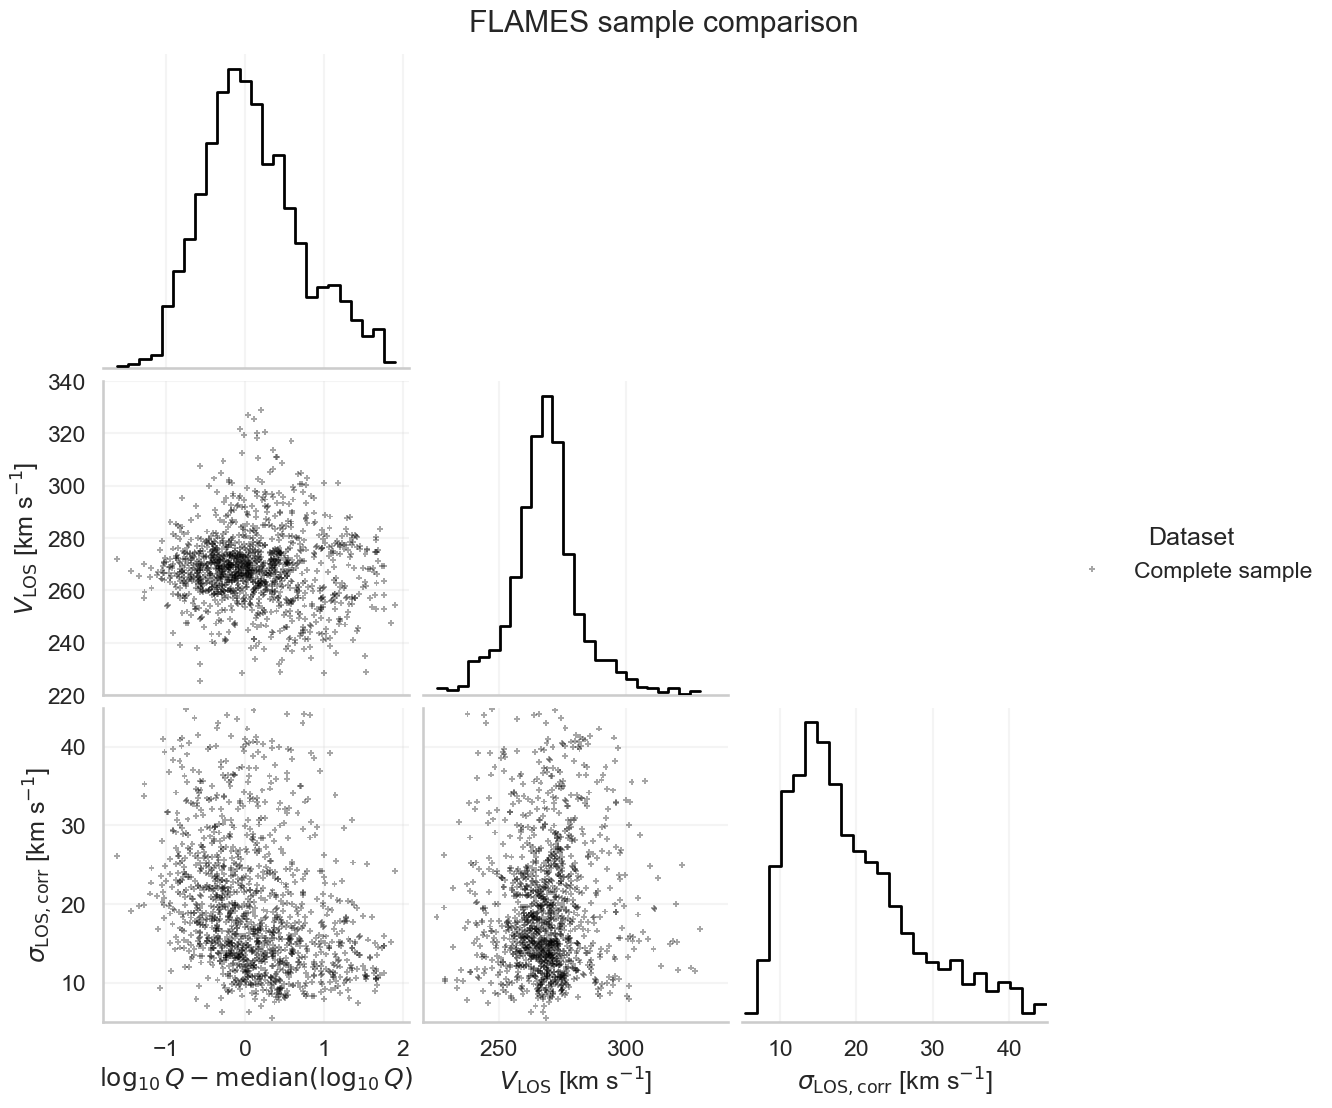

In [13]:

sns.set_context("talk")

# ============================================================
# 1. USER INPUTS
# ============================================================

PAIR_COMPARE = [
    #"regular",
    # "irregular",
    # "stellar",
     "complete",
    #"all_in_regular_area",
    #"cube",
]

PAIR_VARIABLES = ["brightness", "velocity", "sigma"]

# Inclusive selection limits; None keeps all finite values.
PAIR_LIMITS = {
    "brightness": None,
    "velocity": (220, 340),
    "sigma": (5, 45),
}

N_BINS = 25
POINT_SIZE = 18
POINT_ALPHA = 0.35
PANEL_HEIGHT = 3.6

SAVE_FIGURE = True
OUTPUT_DIR = Path("Imgs")
OUTPUT_NAME = "FLAMES_pairplot_comparison_complete"

sample_colors = {
    "regular": "red",
    "all_in_regular_area": "green",
    "cube": "blue",
    "irregular": "orange",
    "stellar": "purple",
    "complete": "black",
}

sample_markers = {
    "regular": "o",
    "all_in_regular_area": "s",
    "cube": "^",
    "irregular": "D",
    "stellar": "v",
    "complete": "P",
}

axis_labels = {
    "brightness": r"$\log_{10} Q - \mathrm{median}(\log_{10} Q)$",
    #"brightness": r"$\log_{10} Q$",
    "velocity": r"$V_{\mathrm{LOS}}$ [km s$^{-1}$]",
    "sigma": r"$\sigma_{\mathrm{LOS,corr}}$ [km s$^{-1}$]",
}

# ============================================================
# 2. PREPARE DATA DIRECTLY FROM THE LOADED FITS
# ============================================================

def normalize_log_brightness(values):
    """Center finite logarithmic brightness values on their median."""
    values = np.asarray(values, dtype=float).copy()
    finite = np.isfinite(values)
    values[~finite] = np.nan

    if finite.any():
        values[finite] -= np.median(values[finite])

    return values


if not PAIR_COMPARE:
    raise ValueError("Select at least one dataset in PAIR_COMPARE.")

pair_frames = []
pair_counts = []
active_keys = []

for key in PAIR_COMPARE:
    dataset = data[key]

    if dataset["kind"] == "table":
        obs = dataset["observations"]

        inputs = {
            "brightness": normalize_log_brightness(
                obs["log_F"].to_numpy(dtype=float)),
           # "brightness":obs["log_F"].to_numpy(dtype=float),
            "velocity": obs["V_mean"].to_numpy(dtype=float),
            "sigma": obs["sigma"].to_numpy(dtype=float),
        }

    elif dataset["kind"] == "image":
        if dataset["mask"] is None:
            raise ValueError(f"{key}: missing MASK extension.")

        # Stored mask convention: 0 = excluded, 1 = valid.
        excluded = dataset["mask"] == 0

        maps = {
            name: np.where(excluded, np.nan, image)
            for name, image in dataset["maps"].items()
        }

        intensity = maps["MOM0"].ravel()
        log_intensity = np.full(intensity.shape, np.nan)

        positive = np.isfinite(intensity) & (intensity > 0)
        log_intensity[positive] = np.log10(intensity[positive])

        inputs = {
            "brightness": normalize_log_brightness(log_intensity),
            "velocity": maps["MOM1"].ravel(),
            # MOM2 already contains corrected LOS sigma.
            "sigma": maps["MOM2"].ravel(),
        }

    else:
        raise ValueError(f"Unknown dataset kind: {dataset['kind']}")

    df = pd.DataFrame({
        variable: np.asarray(inputs[variable], dtype=float).ravel()
        for variable in PAIR_VARIABLES
    })

    n_original = len(df)

    # Use the same rows in every pairplot panel.
    df = (
        df.replace([np.inf, -np.inf], np.nan)
        .dropna(subset=PAIR_VARIABLES)
    )

    if "sigma" in PAIR_VARIABLES:
        df = df.loc[df["sigma"] >= 0].copy()

    for variable in PAIR_VARIABLES:
        limits = PAIR_LIMITS.get(variable)

        if limits is not None:
            low, high = limits

            if low >= high:
                raise ValueError(f"Invalid limits for {variable}.")

            df = df.loc[df[variable].between(low, high)].copy()

    pair_counts.append({
        "Dataset": dataset["label"],
        "N plotted": len(df),
        "N omitted": n_original - len(df),
    })

    if not df.empty:
        df["Dataset"] = dataset["label"]
        pair_frames.append(df)
        active_keys.append(key)

display(pd.DataFrame(pair_counts))

if not pair_frames:
    raise ValueError("No valid rows remain after filtering.")

pair_data = pd.concat(pair_frames, ignore_index=True)

hue_order = [data[key]["label"] for key in active_keys]

pair_palette = {
    data[key]["label"]: sample_colors[key]
    for key in active_keys
}

markers = [sample_markers[key] for key in active_keys]

# ============================================================
# 3. PLOT
# ============================================================

with sns.axes_style("whitegrid"):
    g = sns.pairplot(
        data=pair_data,
        vars=PAIR_VARIABLES,
        hue="Dataset",
        hue_order=hue_order,
        palette=pair_palette,
        markers=markers,
        corner=True,
        diag_kind="hist",
        height=PANEL_HEIGHT,
        grid_kws={
            "diag_sharey": False,
        },
        plot_kws={
            "s": POINT_SIZE,
            "alpha": POINT_ALPHA,
            "edgecolor": "none",
        },
        diag_kws={
            "bins": N_BINS,
            "stat": "density",
            "common_norm": False,
            "common_bins": True,
            "multiple": "layer",
            "element": "step",
            "fill": False,
            "linewidth": 2,
        },
    )

    for row_index, y_variable in enumerate(PAIR_VARIABLES):
        for col_index, x_variable in enumerate(PAIR_VARIABLES):
            ax = g.axes[row_index, col_index]

            if ax is None:
                continue

            xlimits = PAIR_LIMITS.get(x_variable)
            ylimits = PAIR_LIMITS.get(y_variable)

            if xlimits is not None:
                ax.set_xlim(*xlimits)

            if row_index != col_index and ylimits is not None:
                ax.set_ylim(*ylimits)

            if ax.get_xlabel():
                ax.set_xlabel(axis_labels[x_variable])

            if ax.get_ylabel():
                ax.set_ylabel(axis_labels[y_variable])

            ax.grid(alpha=0.2)

    g.figure.suptitle("FLAMES sample comparison", y=1.02)

    # ========================================================
    # 4. OPTIONAL EXPORT
    # ========================================================

    if SAVE_FIGURE:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

        for extension in ["pdf", "png"]:
            g.figure.savefig(
                OUTPUT_DIR / f"{OUTPUT_NAME}.{extension}",
                dpi=300,
                bbox_inches="tight",
                facecolor="white",
            )

    plt.show()

Regular grid: 27 / 27 SF bins plotted
Irregular grid: 40 / 40 SF bins plotted
Stellar grid: 42 / 42 SF bins plotted
Complete sample: 42 / 42 SF bins plotted
All in regular area: 39 / 39 SF bins plotted
Cube: 26 / 32 SF bins plotted


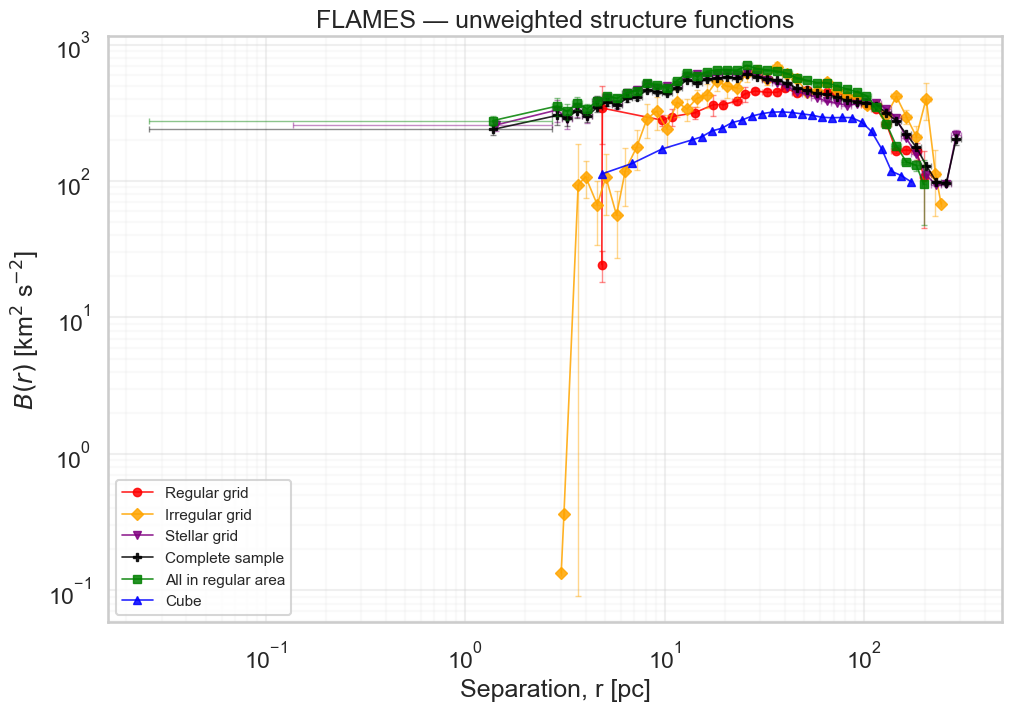

In [14]:

# ============================================================
# 1. USER INPUTS
# ============================================================

SF_COMPARE = [
    "regular",
    "irregular",
    "stellar",
    "complete",
    "all_in_regular_area",
    "cube",
]

GRID_R_UNIT = "pc"           # "pc" or "arcsec"

NORMALIZE_BY_SIG2 = False    # True plots B(r) / header SIG2
SHOW_ERRORS = True

FIGSIZE = (10, 7)
XLIM = None                 # Example: (1, 300)
YLIM = None

SAVE_FIGURE = True
OUTPUT_DIR = Path("Imgs")
OUTPUT_NAME = "FLAMES_structure_functions"

sf_colors = {
    "regular": "red",
    "all_in_regular_area": "green",
    "cube": "blue",
    "irregular": "orange",
    "stellar": "purple",
    "complete": "black",
}

sf_markers = {
    "regular": "o",
    "all_in_regular_area": "s",
    "cube": "^",
    "irregular": "D",
    "stellar": "v",
    "complete": "P",
}

# ============================================================
# 2. LOAD AND PREPARE STORED STRUCTURE FUNCTIONS
# ============================================================

sf_plot_data = {}

for key in SF_COMPARE:
    dataset = data[key]
    sf = dataset["sf"]
    header = dataset["header"]

    B = sf["Unweighted B(r)"].to_numpy(dtype=float)

    if dataset["kind"] == "table":

        r = sf["r"].to_numpy(dtype=float)

        if GRID_R_UNIT == "pc":
            factor = 1.0
        elif GRID_R_UNIT == "arcsec":
            factor = float(header["PC"])
        else:
            raise ValueError("GRID_R_UNIT must be 'pc' or 'arcsec'.")

        r = r * factor

        r_err = (
            sf["r_err"].to_numpy(dtype=float) * factor
            if "r_err" in sf.columns
            else None
        )

    else:
        # Cube SF separation is stored logarithmically in pixels.
        factor = float(header["PIX"]) * float(header["PC"])

        if not np.isfinite(factor) or factor <= 0:
            raise ValueError(f"{key}: invalid PIX × PC conversion.")

        r = 10.0**sf["log10 r"].to_numpy(dtype=float) * factor
        r_err = None

    B_err = (
        sf["Unweighted B(r)_err"].to_numpy(dtype=float)
        if "Unweighted B(r)_err" in sf.columns
        else None
    )

    if NORMALIZE_BY_SIG2:
        sig2 = float(header["SIG2"])

        if not np.isfinite(sig2) or sig2 <= 0:
            raise ValueError(f"{key}: invalid header SIG2.")

        B = B / sig2

        if B_err is not None:
            B_err = B_err / sig2

    # Positive finite values are required for logarithmic axes.
    valid = (
        np.isfinite(r)
        & np.isfinite(B)
        & (r > 0)
        & (B > 0)
    )

    if "N pairs" in sf.columns:
        valid &= sf["N pairs"].to_numpy(dtype=float) > 0

    # Keep bins with missing uncertainties; omit only their error bars.
    order = np.argsort(r[valid])

    sf_plot_data[key] = {
        "r": r[valid][order],
        "B": B[valid][order],
        "r_err": r_err[valid][order] if r_err is not None else None,
        "B_err": B_err[valid][order] if B_err is not None else None,
    }

    print(
        f"{dataset['label']}: "
        f"{valid.sum()} / {len(sf)} SF bins plotted"
    )

# ============================================================
# 3. PLOT
# ============================================================

with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(
        figsize=FIGSIZE,
        constrained_layout=True,
    )

    for key in SF_COMPARE:
        values = sf_plot_data[key]
        r = values["r"]
        B = values["B"]

        if r.size == 0:
            continue

        ax.plot(
            r,
            B,
            marker=sf_markers[key],
            color=sf_colors[key],
            linestyle="-",
            linewidth=1.2,
            markersize=6,
            alpha=0.85,
            label=data[key]["label"],
        )

        if SHOW_ERRORS:
            # Draw uncertainties separately so missing errors
            # never remove valid SF measurements.
            for error_name, coordinate in [
                ("r_err", r),
                ("B_err", B),
            ]:
                error = values[error_name]

                if error is None:
                    continue

                good = np.isfinite(error) & (error >= 0)

                # Avoid nonpositive lower endpoints on logarithmic axes.
                good &= (coordinate - error) > 0

                kwargs = (
                    {"xerr": error[good]}
                    if error_name == "r_err"
                    else {"yerr": error[good]}
                )

                ax.errorbar(
                    r[good],
                    B[good],
                    **kwargs,
                    fmt="none",
                    ecolor=sf_colors[key],
                    elinewidth=1,
                    alpha=0.45,
                    capsize=2,
                )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel("Separation, r [pc]")

    if NORMALIZE_BY_SIG2:
        ax.set_ylabel(r"$B(r) / \sigma_{\mathrm{pos}}^2$")
    else:
        ax.set_ylabel(r"$B(r)$ [km$^2$ s$^{-2}$]")

    if XLIM is not None:
        ax.set_xlim(*XLIM)

    if YLIM is not None:
        ax.set_ylim(*YLIM)

    ax.set_title("FLAMES — unweighted structure functions")
    ax.grid(which="major", alpha=0.3)
    ax.grid(which="minor", alpha=0.1)
    ax.legend(fontsize=11)

    if SAVE_FIGURE:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

        for extension in ["pdf", "png"]:
            fig.savefig(
                OUTPUT_DIR / f"{OUTPUT_NAME}.{extension}",
                dpi=300,
                bbox_inches="tight",
                facecolor="white",
            )

    plt.show()

Regular grid: 27 / 27 SF bins plotted
Irregular grid: 40 / 40 SF bins plotted
Stellar grid: 42 / 42 SF bins plotted
Complete sample: 42 / 42 SF bins plotted
All in regular area: 39 / 39 SF bins plotted
Cube: 26 / 32 SF bins plotted


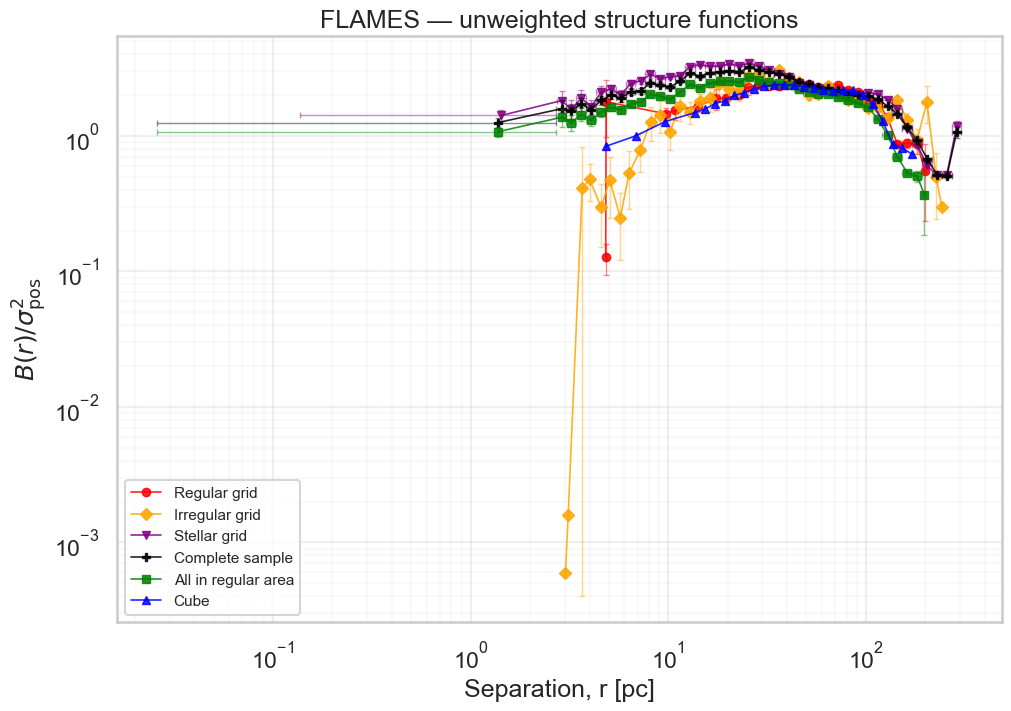

In [15]:

# ============================================================
# 1. USER INPUTS
# ============================================================

SF_COMPARE = [
    "regular",
    "irregular",
    "stellar",
    "complete",
    "all_in_regular_area",
    "cube",
]

GRID_R_UNIT = "pc"           # "pc" or "arcsec"

NORMALIZE_BY_SIG2 = True    # True plots B(r) / header SIG2
SHOW_ERRORS = True

FIGSIZE = (10, 7)
XLIM = None                 # Example: (1, 300)
YLIM = None

SAVE_FIGURE = True
OUTPUT_DIR = Path("Imgs")
OUTPUT_NAME = "FLAMES_structure_functions_norm"

sf_colors = {
    "regular": "red",
    "all_in_regular_area": "green",
    "cube": "blue",
    "irregular": "orange",
    "stellar": "purple",
    "complete": "black",
}

sf_markers = {
    "regular": "o",
    "all_in_regular_area": "s",
    "cube": "^",
    "irregular": "D",
    "stellar": "v",
    "complete": "P",
}

# ============================================================
# 2. LOAD AND PREPARE STORED STRUCTURE FUNCTIONS
# ============================================================

sf_plot_data = {}

for key in SF_COMPARE:
    dataset = data[key]
    sf = dataset["sf"]
    header = dataset["header"]

    B = sf["Unweighted B(r)"].to_numpy(dtype=float)

    if dataset["kind"] == "table":

        r = sf["r"].to_numpy(dtype=float)

        if GRID_R_UNIT == "pc":
            factor = 1.0
        elif GRID_R_UNIT == "arcsec":
            factor = float(header["PC"])
        else:
            raise ValueError("GRID_R_UNIT must be 'pc' or 'arcsec'.")

        r = r * factor

        r_err = (
            sf["r_err"].to_numpy(dtype=float) * factor
            if "r_err" in sf.columns
            else None
        )

    else:
        # Cube SF separation is stored logarithmically in pixels.
        factor = float(header["PIX"]) * float(header["PC"])

        if not np.isfinite(factor) or factor <= 0:
            raise ValueError(f"{key}: invalid PIX × PC conversion.")

        r = 10.0**sf["log10 r"].to_numpy(dtype=float) * factor
        r_err = None

    B_err = (
        sf["Unweighted B(r)_err"].to_numpy(dtype=float)
        if "Unweighted B(r)_err" in sf.columns
        else None
    )

    if NORMALIZE_BY_SIG2:
        sig2 = float(header["SIG2"])

        if not np.isfinite(sig2) or sig2 <= 0:
            raise ValueError(f"{key}: invalid header SIG2.")

        B = B / sig2

        if B_err is not None:
            B_err = B_err / sig2

    # Positive finite values are required for logarithmic axes.
    valid = (
        np.isfinite(r)
        & np.isfinite(B)
        & (r > 0)
        & (B > 0)
    )

    if "N pairs" in sf.columns:
        valid &= sf["N pairs"].to_numpy(dtype=float) > 0

    # Keep bins with missing uncertainties; omit only their error bars.
    order = np.argsort(r[valid])

    sf_plot_data[key] = {
        "r": r[valid][order],
        "B": B[valid][order],
        "r_err": r_err[valid][order] if r_err is not None else None,
        "B_err": B_err[valid][order] if B_err is not None else None,
    }

    print(
        f"{dataset['label']}: "
        f"{valid.sum()} / {len(sf)} SF bins plotted"
    )

# ============================================================
# 3. PLOT
# ============================================================

with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(
        figsize=FIGSIZE,
        constrained_layout=True,
    )

    for key in SF_COMPARE:
        values = sf_plot_data[key]
        r = values["r"]
        B = values["B"]

        if r.size == 0:
            continue

        ax.plot(
            r,
            B,
            marker=sf_markers[key],
            color=sf_colors[key],
            linestyle="-",
            linewidth=1.2,
            markersize=6,
            alpha=0.85,
            label=data[key]["label"],
        )

        if SHOW_ERRORS:
            # Draw uncertainties separately so missing errors
            # never remove valid SF measurements.
            for error_name, coordinate in [
                ("r_err", r),
                ("B_err", B),
            ]:
                error = values[error_name]

                if error is None:
                    continue

                good = np.isfinite(error) & (error >= 0)

                # Avoid nonpositive lower endpoints on logarithmic axes.
                good &= (coordinate - error) > 0

                kwargs = (
                    {"xerr": error[good]}
                    if error_name == "r_err"
                    else {"yerr": error[good]}
                )

                ax.errorbar(
                    r[good],
                    B[good],
                    **kwargs,
                    fmt="none",
                    ecolor=sf_colors[key],
                    elinewidth=1,
                    alpha=0.45,
                    capsize=2,
                )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel("Separation, r [pc]")

    if NORMALIZE_BY_SIG2:
        ax.set_ylabel(r"$B(r) / \sigma_{\mathrm{pos}}^2$")
    else:
        ax.set_ylabel(r"$B(r)$ [km$^2$ s$^{-2}$]")

    if XLIM is not None:
        ax.set_xlim(*XLIM)

    if YLIM is not None:
        ax.set_ylim(*YLIM)

    ax.set_title("FLAMES — unweighted structure functions")
    ax.grid(which="major", alpha=0.3)
    ax.grid(which="minor", alpha=0.1)
    ax.legend(fontsize=11)

    if SAVE_FIGURE:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

        for extension in ["pdf", "png"]:
            fig.savefig(
                OUTPUT_DIR / f"{OUTPUT_NAME}.{extension}",
                dpi=300,
                bbox_inches="tight",
                facecolor="white",
            )

    plt.show()

Regular grid: 27 / 27 SF bins plotted
Irregular grid: 40 / 40 SF bins plotted
Stellar grid: 42 / 42 SF bins plotted
Complete sample: 42 / 42 SF bins plotted
All in regular area: 39 / 39 SF bins plotted
Cube: 26 / 32 SF bins plotted


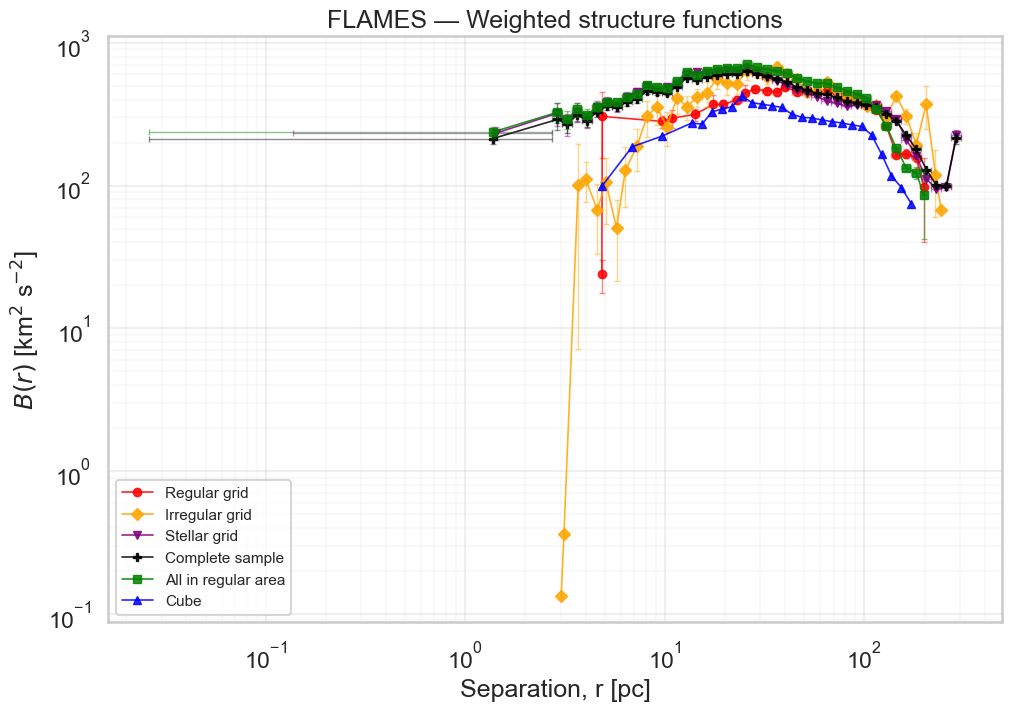

In [16]:

# ============================================================
# 1. USER INPUTS
# ============================================================

SF_COMPARE = [
    "regular",
    "irregular",
    "stellar",
    "complete",
    "all_in_regular_area",
    "cube",
]

GRID_R_UNIT = "pc"           # "pc" or "arcsec"

NORMALIZE_BY_SIG2 = False    # True plots B(r) / header SIG2
SHOW_ERRORS = True

FIGSIZE = (10, 7)
XLIM = None                 # Example: (1, 300)
YLIM = None

SAVE_FIGURE = True
OUTPUT_DIR = Path("Imgs")
OUTPUT_NAME = "FLAMES_structure_functions_weighted"

sf_colors = {
    "regular": "red",
    "all_in_regular_area": "green",
    "cube": "blue",
    "irregular": "orange",
    "stellar": "purple",
    "complete": "black",
}

sf_markers = {
    "regular": "o",
    "all_in_regular_area": "s",
    "cube": "^",
    "irregular": "D",
    "stellar": "v",
    "complete": "P",
}

# ============================================================
# 2. LOAD AND PREPARE STORED STRUCTURE FUNCTIONS
# ============================================================

sf_plot_data = {}

for key in SF_COMPARE:
    dataset = data[key]
    sf = dataset["sf"]
    header = dataset["header"]

    B = sf["Weighted B(r)"].to_numpy(dtype=float)

    if dataset["kind"] == "table":

        r = sf["r"].to_numpy(dtype=float)

        if GRID_R_UNIT == "pc":
            factor = 1.0
        elif GRID_R_UNIT == "arcsec":
            factor = float(header["PC"])
        else:
            raise ValueError("GRID_R_UNIT must be 'pc' or 'arcsec'.")

        r = r * factor

        r_err = (
            sf["r_err"].to_numpy(dtype=float) * factor
            if "r_err" in sf.columns
            else None
        )

    else:
        # Cube SF separation is stored logarithmically in pixels.
        factor = float(header["PIX"]) * float(header["PC"])

        if not np.isfinite(factor) or factor <= 0:
            raise ValueError(f"{key}: invalid PIX × PC conversion.")

        r = 10.0**sf["log10 r"].to_numpy(dtype=float) * factor
        r_err = None

    B_err = (
        sf["Weighted B(r)_err"].to_numpy(dtype=float)
        if "Weighted B(r)_err" in sf.columns
        else None
    )

    if NORMALIZE_BY_SIG2:
        sig2 = float(header["SIG2"])

        if not np.isfinite(sig2) or sig2 <= 0:
            raise ValueError(f"{key}: invalid header SIG2.")

        B = B / sig2

        if B_err is not None:
            B_err = B_err / sig2

    # Positive finite values are required for logarithmic axes.
    valid = (
        np.isfinite(r)
        & np.isfinite(B)
        & (r > 0)
        & (B > 0)
    )

    if "N pairs" in sf.columns:
        valid &= sf["N pairs"].to_numpy(dtype=float) > 0

    # Keep bins with missing uncertainties; omit only their error bars.
    order = np.argsort(r[valid])

    sf_plot_data[key] = {
        "r": r[valid][order],
        "B": B[valid][order],
        "r_err": r_err[valid][order] if r_err is not None else None,
        "B_err": B_err[valid][order] if B_err is not None else None,
    }

    print(
        f"{dataset['label']}: "
        f"{valid.sum()} / {len(sf)} SF bins plotted"
    )

# ============================================================
# 3. PLOT
# ============================================================

with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(
        figsize=FIGSIZE,
        constrained_layout=True,
    )

    for key in SF_COMPARE:
        values = sf_plot_data[key]
        r = values["r"]
        B = values["B"]

        if r.size == 0:
            continue

        ax.plot(
            r,
            B,
            marker=sf_markers[key],
            color=sf_colors[key],
            linestyle="-",
            linewidth=1.2,
            markersize=6,
            alpha=0.85,
            label=data[key]["label"],
        )

        if SHOW_ERRORS:
            # Draw uncertainties separately so missing errors
            # never remove valid SF measurements.
            for error_name, coordinate in [
                ("r_err", r),
                ("B_err", B),
            ]:
                error = values[error_name]

                if error is None:
                    continue

                good = np.isfinite(error) & (error >= 0)

                # Avoid nonpositive lower endpoints on logarithmic axes.
                good &= (coordinate - error) > 0

                kwargs = (
                    {"xerr": error[good]}
                    if error_name == "r_err"
                    else {"yerr": error[good]}
                )

                ax.errorbar(
                    r[good],
                    B[good],
                    **kwargs,
                    fmt="none",
                    ecolor=sf_colors[key],
                    elinewidth=1,
                    alpha=0.45,
                    capsize=2,
                )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel("Separation, r [pc]")

    if NORMALIZE_BY_SIG2:
        ax.set_ylabel(r"$B(r) / \sigma_{\mathrm{pos}}^2$")
    else:
        ax.set_ylabel(r"$B(r)$ [km$^2$ s$^{-2}$]")

    if XLIM is not None:
        ax.set_xlim(*XLIM)

    if YLIM is not None:
        ax.set_ylim(*YLIM)

    ax.set_title("FLAMES — Weighted structure functions")
    ax.grid(which="major", alpha=0.3)
    ax.grid(which="minor", alpha=0.1)
    ax.legend(fontsize=11)

    if SAVE_FIGURE:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

        for extension in ["pdf", "png"]:
            fig.savefig(
                OUTPUT_DIR / f"{OUTPUT_NAME}.{extension}",
                dpi=300,
                bbox_inches="tight",
                facecolor="white",
            )

    plt.show()

Regular grid / Unweighted: 27 bins
Regular grid / Weighted: 27 bins
Cube / Unweighted: 26 bins
Cube / Weighted: 26 bins
grid_2 / Unweighted: 24 bins
grid_2 / Weighted: 24 bins
grid2matrix / Unweighted: 24 bins
grid2matrix / Weighted: 24 bins
matrix2grid / Unweighted: 26 bins
matrix2grid / Weighted: 26 bins


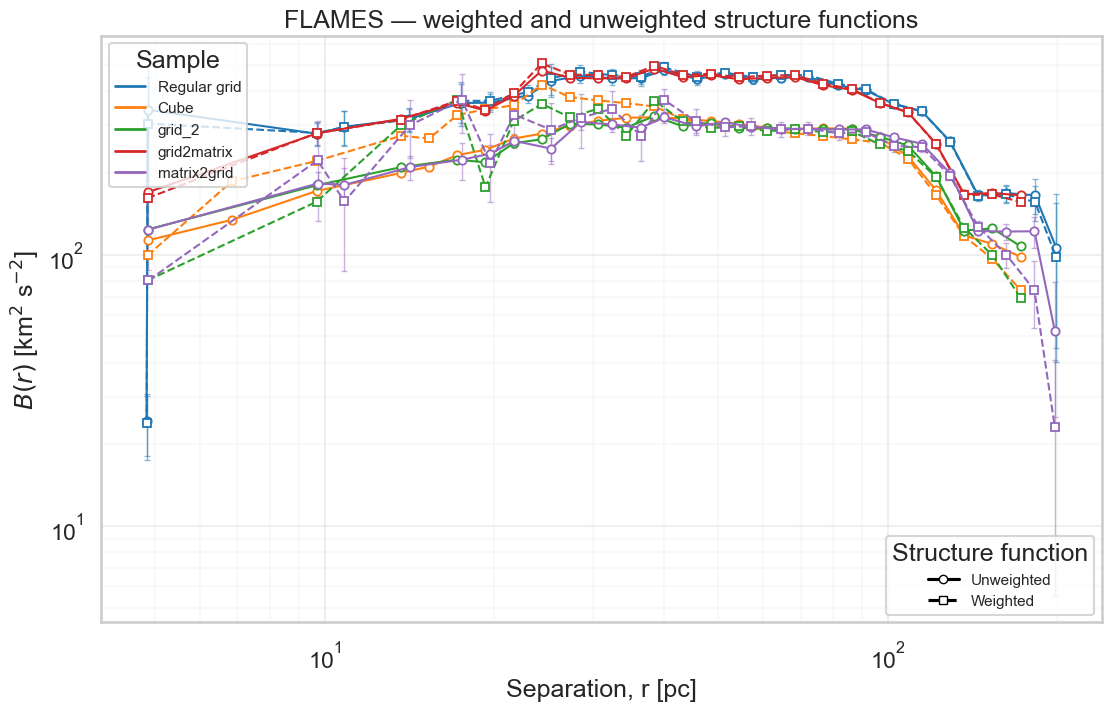

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from matplotlib.lines import Line2D

sns.set_context("talk")

# ============================================================
# 1. USER INPUTS
# ============================================================

SF_COMPARE = [
    "regular",
    # "irregular",
    # "stellar",
    #"complete",
    #"all_in_regular_area",
    #"grid_0",
    #"grid_1",
    "cube",
     "grid_2",
    "grid2matrix",
    "matrix2grid"
]

# Confirm against the units used when exporting your grid SFs.
GRID_R_UNIT = "pc"       # "pc" or "arcsec"

FIGSIZE = (11, 7)
SHOW_ERRORS = True

XLIM = None
YLIM = None

SAVE_FIGURE = True
OUTPUT_DIR = Path("Imgs")
OUTPUT_NAME = "FLAMES_SF_regular_comp"

# Gray shades for the selected samples.
#sf_palette = dict(zip(
#    SF_COMPARE,
#    map(str, np.linspace(0.0, 0.65, len(SF_COMPARE))),
#))
# Choose a colormap: "tab10", "Set1", "Dark2", "viridis", etc.
CMAP_NAME = "tab10"

colors = sns.color_palette(CMAP_NAME, n_colors=len(SF_COMPARE))

sf_palette = dict(zip(SF_COMPARE, colors))


sf_styles = {
    "Unweighted": {
        "column": "Unweighted B(r)",
        "error_column": "Unweighted B(r)_err",
        "marker": "o",
        "linestyle": "-",
    },
    "Weighted": {
        "column": "Weighted B(r)",
        "error_column": "Weighted B(r)_err",
        "marker": "s",
        "linestyle": "--",
    },
}

# ============================================================
# 2. PLOT STORED STRUCTURE FUNCTIONS
# ============================================================

plotted_samples = []
plotted_types = set()

with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(
        figsize=FIGSIZE,
        constrained_layout=True,
    )

    for key in SF_COMPARE:
        dataset = data[key]
        sf = dataset["sf"]
        header = dataset["header"]

        # ----------------------------------------------------
        # Separation in parsecs
        # ----------------------------------------------------

#        if dataset["kind"] == "table":
#            if GRID_R_UNIT == "pc":
#                factor = 1.0
#            elif GRID_R_UNIT == "arcsec":
#                factor = float(header["PC"])
#            else:
#                raise ValueError(
#                    "GRID_R_UNIT must be 'pc' or 'arcsec'."
#                )

#            r = sf["r"].to_numpy(dtype=float) * factor

#        else:
#            factor = float(header["PIX"]) * float(header["PC"])

#            if not np.isfinite(factor) or factor <= 0:
#                raise ValueError(f"{key}: invalid PIX × PC.")

#            r = (
#                10.0**sf["log10 r"].to_numpy(dtype=float)
#                * factor
#            )

#        sample_plotted = False

        # ----------------------------------------------------
        # Separation in parsecs
        # ----------------------------------------------------

        if key == "matrix2grid":
            # Scattered SF export: r is already in parsecs,
            # even though the observations are stored as images.
            r = sf["r"].to_numpy(dtype=float)

        elif dataset["kind"] == "table":
            if GRID_R_UNIT == "pc":
                factor = 1.0
            elif GRID_R_UNIT == "arcsec":
                factor = float(header["PC"])
            else:
                raise ValueError(
                    "GRID_R_UNIT must be 'pc' or 'arcsec'."
                )

            r = sf["r"].to_numpy(dtype=float) * factor

        else:
            # Matrix SF export: log10 r is in pixel units.
            factor = float(header["PIX"]) * float(header["PC"])

            if not np.isfinite(factor) or factor <= 0:
                raise ValueError(f"{key}: invalid PIX × PC.")

            r = (
                10.0**sf["log10 r"].to_numpy(dtype=float)
                * factor
            )
        
        # ----------------------------------------------------
        # Weighted and unweighted curves
        # ----------------------------------------------------

        for sf_type, style in sf_styles.items():
            column = style["column"]

            if column not in sf.columns:
                print(
                    f"{dataset['label']}: missing '{column}'; "
                    "skipping this curve."
                )
                continue

            B = sf[column].to_numpy(dtype=float)

            valid = (
                np.isfinite(r)
                & np.isfinite(B)
                & (r > 0)
                & (B > 0)
            )

            if "N pairs" in sf.columns:
                valid &= sf["N pairs"].to_numpy(dtype=float) > 0

            if not valid.any():
                print(f"{dataset['label']} / {sf_type}: no valid bins.")
                continue

            order = np.argsort(r[valid])
            rr = r[valid][order]
            bb = B[valid][order]

            ax.plot(
                rr,
                bb,
                color=sf_palette[key],
                marker=style["marker"],
                linestyle=style["linestyle"],
                linewidth=1.5,
                markersize=6,
                markerfacecolor="white",
                markeredgewidth=1.3,
                zorder=3,
            )

            # Use only the uncertainty belonging to this SF type.
            error_column = style["error_column"]

            if SHOW_ERRORS and error_column in sf.columns:
                error = sf[error_column].to_numpy(dtype=float)
                error = error[valid][order]

                good_error = (
                    np.isfinite(error)
                    & (error >= 0)
                    & (bb - error > 0)
                )

                ax.errorbar(
                    rr[good_error],
                    bb[good_error],
                    yerr=error[good_error],
                    fmt="none",
                    ecolor=sf_palette[key],
                    elinewidth=1,
                    capsize=2,
                    alpha=0.5,
                    zorder=2,
                )

            print(
                f"{dataset['label']} / {sf_type}: "
                f"{len(rr)} bins"
            )

            sample_plotted = True
            plotted_types.add(sf_type)

        if sample_plotted:
            plotted_samples.append(key)

    # ========================================================
    # 3. AXES AND LEGENDS
    # ========================================================

    ax.set(
        xscale="log",
        yscale="log",
        xlabel="Separation, r [pc]",
        ylabel=r"$B(r)$ [km$^2$ s$^{-2}$]",
        title="FLAMES — weighted and unweighted structure functions",
    )

    if XLIM is not None:
        ax.set_xlim(*XLIM)

    if YLIM is not None:
        ax.set_ylim(*YLIM)

    ax.grid(which="major", alpha=0.3)
    ax.grid(which="minor", alpha=0.1)

    # Gray shade identifies the sample.
    sample_handles = [
        Line2D(
            [0], [0],
            color=sf_palette[key],
            linewidth=2,
            label=data[key]["label"],
        )
        for key in plotted_samples
    ]

    sample_legend = ax.legend(
        handles=sample_handles,
        title="Sample",
        loc="upper left",
        fontsize=11,
    )
    ax.add_artist(sample_legend)

    # Marker and line style identify the estimator.
    type_handles = [
        Line2D(
            [0], [0],
            color="black",
            marker=style["marker"],
            linestyle=style["linestyle"],
            markerfacecolor="white",
            markersize=6,
            label=sf_type,
        )
        for sf_type, style in sf_styles.items()
        if sf_type in plotted_types
    ]

    ax.legend(
        handles=type_handles,
        title="Structure function",
        loc="lower right",
        fontsize=11,
    )

    # ========================================================
    # 4. OPTIONAL EXPORT
    # ========================================================

    if SAVE_FIGURE:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

        for extension in ["pdf", "png"]:
            fig.savefig(
                OUTPUT_DIR / f"{OUTPUT_NAME}.{extension}",
                dpi=300,
                bbox_inches="tight",
                facecolor="white",
            )

    plt.show()

Regular grid: 27 / 27 SF bins plotted
Cube: 26 / 32 SF bins plotted
grid_2: 24 / 32 SF bins plotted
grid2matrix: 24 / 32 SF bins plotted
matrix2grid: 26 / 26 SF bins plotted


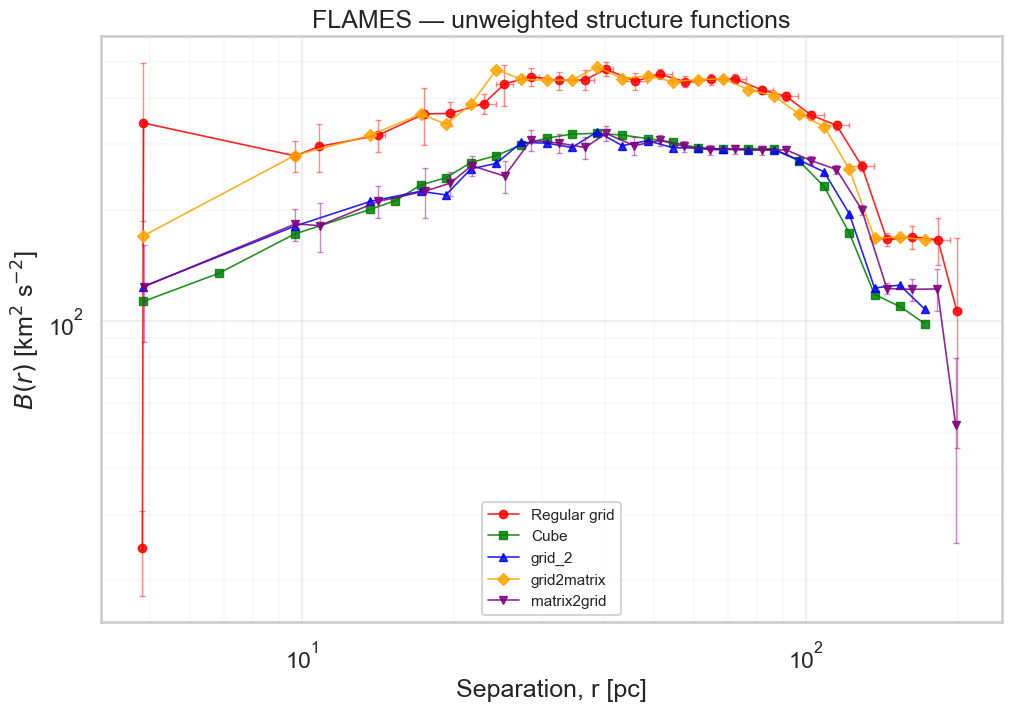

In [21]:
# ============================================================
# 1. USER INPUTS
# ============================================================

SF_COMPARE = [
    "regular",
    # "irregular",
    # "stellar",
    #"complete",
    #"all_in_regular_area",
    #"grid_0",
    #"grid_1",
    "cube",
     "grid_2",
    "grid2matrix",
    "matrix2grid"
]

GRID_R_UNIT = "pc"           # "pc" or "arcsec"

NORMALIZE_BY_SIG2 = False    # True plots B(r) / header SIG2
SHOW_ERRORS = True

FIGSIZE = (10, 7)
XLIM = None                 # Example: (1, 300)
YLIM = None

SAVE_FIGURE = True
OUTPUT_DIR = Path("Imgs")
OUTPUT_NAME = "FLAMES_structure_functions_regular_cube_comp"

sf_colors = {
    "regular": "red",
    "cube": "green",
    "grid_2": "blue",
    "grid2matrix": "orange",
    "matrix2grid": "purple",
    "complete": "black",
}

sf_markers = {
    "regular": "o",
    "cube": "s",
    "grid_2": "^",
    "grid2matrix": "D",
    "matrix2grid": "v",
    "complete": "P",
}

# ============================================================
# 2. LOAD AND PREPARE STORED STRUCTURE FUNCTIONS
# ============================================================

sf_plot_data = {}

for key in SF_COMPARE:
    dataset = data[key]
    sf = dataset["sf"]
    header = dataset["header"]

    B = sf["Unweighted B(r)"].to_numpy(dtype=float)

    if dataset["kind"] == "table":

        r = sf["r"].to_numpy(dtype=float)

        if GRID_R_UNIT == "pc":
            factor = 1.0
        elif GRID_R_UNIT == "arcsec":
            factor = float(header["PC"])
        else:
            raise ValueError("GRID_R_UNIT must be 'pc' or 'arcsec'.")

        r = r * factor

        r_err = (
            sf["r_err"].to_numpy(dtype=float) * factor
            if "r_err" in sf.columns
            else None
        )

    else:
        # Cube SF separation is stored logarithmically in pixels.
        factor = float(header["PIX"]) * float(header["PC"])

        if not np.isfinite(factor) or factor <= 0:
            raise ValueError(f"{key}: invalid PIX × PC conversion.")

        r = 10.0**sf["log10 r"].to_numpy(dtype=float) * factor
        r_err = None

    B_err = (
        sf["Unweighted B(r)_err"].to_numpy(dtype=float)
        if "Unweighted B(r)_err" in sf.columns
        else None
    )

    if NORMALIZE_BY_SIG2:
        sig2 = float(header["SIG2"])

        if not np.isfinite(sig2) or sig2 <= 0:
            raise ValueError(f"{key}: invalid header SIG2.")

        B = B / sig2

        if B_err is not None:
            B_err = B_err / sig2

    # Positive finite values are required for logarithmic axes.
    valid = (
        np.isfinite(r)
        & np.isfinite(B)
        & (r > 0)
        & (B > 0)
    )

    if "N pairs" in sf.columns:
        valid &= sf["N pairs"].to_numpy(dtype=float) > 0

    # Keep bins with missing uncertainties; omit only their error bars.
    order = np.argsort(r[valid])

    sf_plot_data[key] = {
        "r": r[valid][order],
        "B": B[valid][order],
        "r_err": r_err[valid][order] if r_err is not None else None,
        "B_err": B_err[valid][order] if B_err is not None else None,
    }

    print(
        f"{dataset['label']}: "
        f"{valid.sum()} / {len(sf)} SF bins plotted"
    )

# ============================================================
# 3. PLOT
# ============================================================

with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(
        figsize=FIGSIZE,
        constrained_layout=True,
    )

    for key in SF_COMPARE:
        values = sf_plot_data[key]
        r = values["r"]
        B = values["B"]

        if r.size == 0:
            continue

        ax.plot(
            r,
            B,
            marker=sf_markers[key],
            color=sf_colors[key],
            linestyle="-",
            linewidth=1.2,
            markersize=6,
            alpha=0.85,
            label=data[key]["label"],
        )

        if SHOW_ERRORS:
            # Draw uncertainties separately so missing errors
            # never remove valid SF measurements.
            for error_name, coordinate in [
                ("r_err", r),
                ("B_err", B),
            ]:
                error = values[error_name]

                if error is None:
                    continue

                good = np.isfinite(error) & (error >= 0)

                # Avoid nonpositive lower endpoints on logarithmic axes.
                good &= (coordinate - error) > 0

                kwargs = (
                    {"xerr": error[good]}
                    if error_name == "r_err"
                    else {"yerr": error[good]}
                )

                ax.errorbar(
                    r[good],
                    B[good],
                    **kwargs,
                    fmt="none",
                    ecolor=sf_colors[key],
                    elinewidth=1,
                    alpha=0.45,
                    capsize=2,
                )

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel("Separation, r [pc]")

    if NORMALIZE_BY_SIG2:
        ax.set_ylabel(r"$B(r) / \sigma_{\mathrm{pos}}^2$")
    else:
        ax.set_ylabel(r"$B(r)$ [km$^2$ s$^{-2}$]")

    if XLIM is not None:
        ax.set_xlim(*XLIM)

    if YLIM is not None:
        ax.set_ylim(*YLIM)

    ax.set_title("FLAMES — unweighted structure functions")
    ax.grid(which="major", alpha=0.3)
    ax.grid(which="minor", alpha=0.1)
    ax.legend(fontsize=11)

    if SAVE_FIGURE:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

        for extension in ["pdf", "png"]:
            fig.savefig(
                OUTPUT_DIR / f"{OUTPUT_NAME}.{extension}",
                dpi=300,
                bbox_inches="tight",
                facecolor="white",
            )

    plt.show()

,,N,Median,Std
Quantity,Dataset,,,
brightness,Regular grid,269,0.000,0.448
velocity,Regular grid,269,265.728,13.822
sigma,Regular grid,261,18.356,7.835
brightness,Cube,959,0.000,0.397
velocity,Cube,959,268.901,11.473
sigma,Cube,918,26.275,6.716


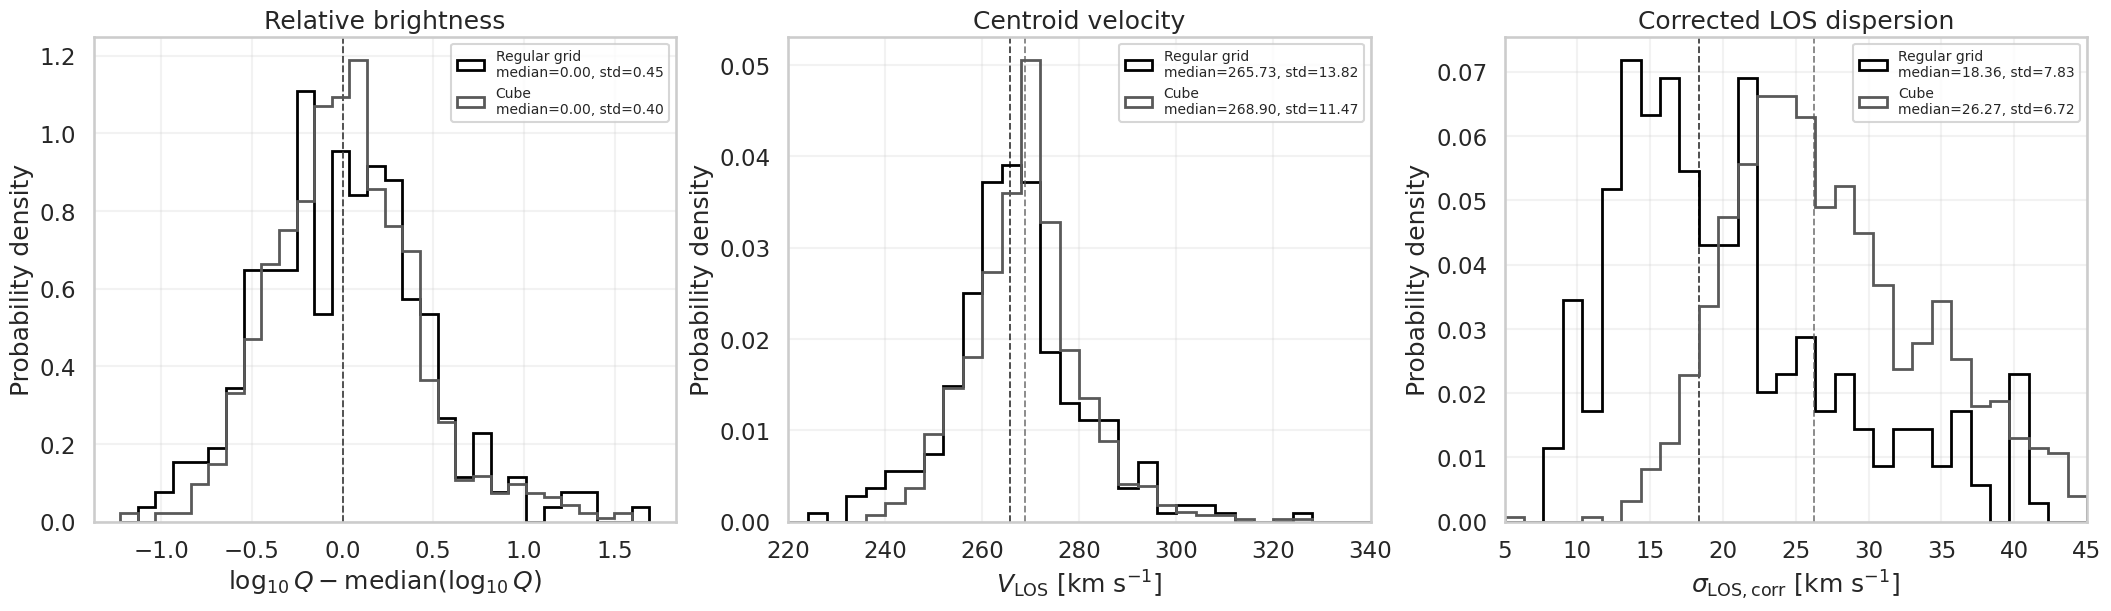

In [20]:
# ============================================================
# 1. USER INPUTS
# ============================================================

COMPARE = [
    "regular",
    # "irregular",
    # "stellar",
    #"complete",
    #"all_in_regular_area",
    #"grid_0",
    #"grid_1",
    "cube",
#    "grid_2",
]

FIGSIZE = (21, 6)
N_BINS = 30

# Inclusive selection limits.
# Histograms and statistics use the same selected values.
LIMITS = {
    "brightness": None,         # Example: (-2, 2)
    "velocity": (220, 340),
    "sigma": (5, 45),
}

# Population standard deviation of the selected values.
DDOF = 0

# ============================================================
# 2. PREPARE DISTRIBUTIONS FROM LOADED FITS DATA
# ============================================================

def center_log_brightness(values):
    values = np.asarray(values, dtype=float).copy()
    finite = np.isfinite(values)
    values[~finite] = np.nan

    if finite.any():
        values[finite] -= np.median(values[finite])

    return values


hist_data = {}

for key in COMPARE:
    dataset = data[key]

    if dataset["kind"] == "table":
        obs = dataset["observations"]

        hist_data[key] = {
            "brightness": center_log_brightness(
                obs["log_F"].to_numpy(dtype=float)
            ),
            "velocity": obs["V_mean"].to_numpy(dtype=float),
            "sigma": obs["sigma"].to_numpy(dtype=float),
        }

    else:
        # Mask convention: 0 = excluded, 1 = valid.
        if dataset["mask"] is None:
            raise ValueError(f"{key}: missing MASK extension.")

        excluded = dataset["mask"] == 0

        maps = {
            name: np.where(excluded, np.nan, image)
            for name, image in dataset["maps"].items()
        }

        intensity = maps["MOM0"].ravel()
        log_intensity = np.full(intensity.shape, np.nan)

        positive = np.isfinite(intensity) & (intensity > 0)
        log_intensity[positive] = np.log10(intensity[positive])

        hist_data[key] = {
            "brightness": center_log_brightness(log_intensity),
            "velocity": maps["MOM1"].ravel(),
            "sigma": maps["MOM2"].ravel(),  # Already corrected sigma
        }

# ============================================================
# 3. SELECT VALUES AND COMPUTE STATISTICS
# ============================================================

variables = ["brightness", "velocity", "sigma"]

selected = {}
statistics = []

for key in COMPARE:
    selected[key] = {}

    for variable in variables:
        values = np.asarray(hist_data[key][variable], dtype=float)

        valid = np.isfinite(values)

        if variable == "sigma":
            valid &= values >= 0

        limits = LIMITS[variable]

        if limits is not None:
            low, high = limits
            if low >= high:
                raise ValueError(f"Invalid limits for {variable}.")
            valid &= (values >= low) & (values <= high)

        x = values[valid]
        selected[key][variable] = x

        statistics.append({
            "Key": key,
            "Dataset": data[key]["label"],
            "Quantity": variable,
            "N": len(x),
            "Median": np.median(x) if len(x) else np.nan,
            "Std": np.std(x, ddof=DDOF) if len(x) > DDOF else np.nan,
        })

stats = pd.DataFrame(statistics)

# Stable colors even when COMPARE changes.
all_keys = list(data)
#palette = dict(zip(
#    all_keys,
#    sns.color_palette("colorblind", len(all_keys)),
#))
# Stable grayscale colors: black to light gray.
all_keys = list(data)

gray_levels = np.linspace(0.0, 0.7, len(all_keys))

palette = {
    key: str(gray)
    for key, gray in zip(all_keys, gray_levels)
}

# ============================================================
# 4. PLOT 1 × 3 PDF HISTOGRAMS
# ============================================================

titles = {
    "brightness": "Relative brightness",
    "velocity": "Centroid velocity",
    "sigma": "Corrected LOS dispersion",
}

axis_labels = {
    "brightness": r"$\log_{10} Q - \mathrm{median}(\log_{10} Q)$",
    "velocity": r"$V_{\mathrm{LOS}}$ [km s$^{-1}$]",
    "sigma": r"$\sigma_{\mathrm{LOS,corr}}$ [km s$^{-1}$]",
}

with sns.axes_style("whitegrid"):
    fig, axes = plt.subplots(
        1, 3,
        figsize=FIGSIZE,
        constrained_layout=True,
    )

    for ax, variable in zip(axes, variables):

        arrays = [
            selected[key][variable]
            for key in COMPARE
            if selected[key][variable].size
        ]

        if not arrays:
            ax.set_title(f"{titles[variable]}: no valid data")
            continue

        # Common bin edges for all samples within this panel.
        edges = np.histogram_bin_edges(
            np.concatenate(arrays),
            bins=N_BINS,
            range=LIMITS[variable],
        )

        for key in COMPARE:
            x = selected[key][variable]

            if x.size == 0:
                continue

            median = np.median(x)
            std = np.std(x, ddof=DDOF) if x.size > DDOF else np.nan

            legend_label = (
                f"{data[key]['label']}\n"
                f"median={median:.2f}, std={std:.2f}"
            )

            ax.hist(
                x,
                bins=edges,
                density=True,
                histtype="step",
                linewidth=2,
                color=palette[key],
                label=legend_label,
            )

            ax.axvline(
                median,
                color=palette[key],
                linestyle="--",
                linewidth=1.3,
                alpha=0.75,
                label="_nolegend_",
            )

        ax.set_title(titles[variable])
        ax.set_xlabel(axis_labels[variable])
        ax.set_ylabel("Probability density")

        if LIMITS[variable] is not None:
            ax.set_xlim(*LIMITS[variable])

        ax.legend(fontsize=10, frameon=True)
        ax.grid(alpha=0.25)

   # plt.show()

# Numerical values, retaining more precision.
display(
    stats.drop(columns="Key")
    .set_index(["Quantity", "Dataset"])
    .round(3)
)


output_dir = Path("Imgs")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "FLAMES_PDFs_comparison_2.pdf",
    bbox_inches="tight",
    facecolor="white",
)

fig.savefig(
    output_dir / "FLAMES_PDFs_comparison_2.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()